# NB-09 · Stage 9 — Prototype index construction

**Project:** HiDMamba, hierarchical distillation for 12-lead ECG (PTB-XL, 100 Hz)
**Runtime:** Kaggle. One forward pass of the frozen DEAN over 19,601 records (about 1 minute on a T4, about 15 minutes on CPU), then CPU-only retrieval. Total about 10 to 15 minutes.

Synopsis, Stage 9: *independently of Stages 4–8, extract frozen DEAN embeddings for the full training set and build a CPU-resident FAISS `IndexFlatIP` for nearest-neighbour prototype retrieval.*

This notebook does exactly that, and then checks that the index is **useful**, not just built:

1. **Extracts** the 256-d DEAN embedding of every training record (folds 1–8, 17,418) and of the validation fold (fold 9, 2,183) from the frozen `dean_finetuned.pt`. It does not read the Chief Resident, the gate, the HODs or the Professors; the Stage-7 cache is used only as a cross-check if it is attached.
2. **Chooses the embedding transform** that is stored with the index (raw cosine, centred cosine, or PCA-whitened cosine) and the retrieval settings (k, softmax temperature) on fold 9 with a two-fold cross-fit, so the reported number is not the one that picked the setting.
3. **Builds two exact indices**: `index_train` (folds 1–8, the one every fold-9 experiment uses) and `index_trainval` (folds 1–9, for the single test evaluation of Stage 10, when fold 9's labels are legitimately known).
4. **Evaluates retrieval**: kNN label scores against the DEAN classification head, a class-prototype baseline, precision and recall of the retrieved neighbours, calibration, learning curve over index size, and an honest look at the in-sample effect (train-against-train retrieval is optimistic because DEAN was trained on those records).
5. **Previews fusion** with the Chief Resident if its outputs are attached (an optional section, decisions stay with Stage 10).
6. **Benchmarks** the CPU index and verifies it: FAISS against a numpy reference, reload from disk, and the deployed `Retriever` class.

### Inputs (attach these Datasets)
| Dataset | Files used |
|---|---|
| `dean-finetuned-v2` (Stage 3) | `dean_finetuned.pt`, `split_idx.npz`, `dean_lib.py`, `eval_lib.py` |
| `ptbxl-processed-v1` (Stage 1) | `ptbxl_100hz.npy`, `labels_multihot.csv` |
| `cached-teacher-outputs-v1` (Stage 7), *optional* | `cache/dean_emb_*.npy` (cross-check of the fresh extraction) |
| `chief-resident-v1` (Stage 8), *optional* | `cr_logits_val.npy`, `cr_calibration.json` (fusion preview only) |

Internet is needed only if `faiss-cpu` is not installed (`pip install faiss-cpu`); without it the notebook falls back to a numpy index with identical results and says so. Fold 10 is never read.

### Outputs (`/kaggle/working`, publish as the Dataset `prototype-index-v1`)
| File | Content |
|---|---|
| `index_train.faiss`, `index_trainval.faiss` | exact inner-product indices over the transformed, L2-normalised embeddings |
| `prototype_meta.npz`, `prototype_config.json` | transform parameters, labels, ecg ids and folds of the indexed records, class prototypes, chosen k and temperature |
| `proto_lib.py` | `Retriever` (load, search, kNN scores) for Stages 10 and later |
| `dean_emb_{train,val}.npy`, `knn_scores_val.npy` | embeddings and the honest fold-9 retrieval scores |
| `prototype_metrics.json`, `tables/*.csv`, `figures/*.png|pdf` | every number and 15 figures, 7.2 in wide (3.5 in single column), 300 dpi |

### Decisions that interpret the plan
* **"Prototype".** The synopsis does not say whether a prototype is a training record or a class centroid. Both are built: the index holds every training record (exemplar retrieval, the standard retrieval-augmented setting), and one L2-normalised mean embedding per label is stored as a class prototype. The comparison between the two is in section 7.
* **Exact search.** At 17,418 vectors of 256 dimensions a flat index answers a query in well under a millisecond on a CPU, so an approximate index would add error and gain nothing. Section 10 measures it.
* **Independence from Stages 4–8.** The index depends on DEAN only. Every later stage can therefore swap its own network without rebuilding it.
* **In-sample embeddings.** DEAN was fine-tuned on the indexed records, so their embeddings are tighter than those of new records. Queries from fold 9 are unseen, which is the honest situation; train-against-train numbers (leave-one-out) are reported but labelled optimistic.

## 0. Environment

In [1]:
import os, sys, glob, json, time, math, copy, random, shutil, warnings, platform, importlib, subprocess
from collections import OrderedDict
from contextlib import nullcontext

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import rankdata, spearmanr

warnings.filterwarnings('ignore', category=UserWarning)
NB_T0 = time.time()
ON_KAGGLE = os.path.exists('/kaggle/working')
WORK = '/kaggle/working' if ON_KAGGLE else os.path.abspath('./working')
INPUT_ROOT = os.environ.get('NB_INPUT_ROOT', '/kaggle/input')
os.makedirs(WORK, exist_ok=True); os.chdir(WORK)
FIG_DIR, TAB_DIR = os.path.join(WORK, 'figures'), os.path.join(WORK, 'tables')
for d in (FIG_DIR, TAB_DIR): os.makedirs(d, exist_ok=True)
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = dev.type == 'cuda'

def amp():
    return torch.autocast('cuda', dtype=torch.float16) if USE_AMP else nullcontext()

def find_art(name, exclude=()):
    hits = sorted(glob.glob(f'{WORK}/**/{name}', recursive=True)) + sorted(glob.glob(f'{INPUT_ROOT}/**/{name}', recursive=True))
    hits = [h for h in hits if not any(e in h for e in exclude)]
    return hits[0] if hits else None

def find_one(name, hint=''):
    p = find_art(name)
    if p is None: raise FileNotFoundError(f'{name} not found. Attach the Dataset {hint or "that contains it"}.')
    return p

VERSIONS = {'python': platform.python_version(), 'torch': torch.__version__, 'numpy': np.__version__, 'pandas': pd.__version__}
print(VERSIONS, '| device', dev, '| work', WORK)

{'python': '3.13.15', 'torch': '2.11.0+cu128', 'numpy': '2.1.3', 'pandas': '2.3.3'} | device cuda | work /kaggle/working


## 1. Configuration
`k_grid`, `tau_grid` and `variants` define the search space of section 5; they are fixed here, before any number is seen. `min_pos` is the reliability rule of every stage (a label is averaged only if fold 9 holds at least 10 positives).

In [2]:
CFG = dict(
    seed=42, min_pos=10, n_boot=300, k_max=100, bs_extract=128,
    k_grid=[5, 10, 20, 50, 100], tau_grid=[0.02, 0.05, 0.1, 0.2, None],            # None = uniform vote
    variants=OrderedDict([
        ('cosine',        dict(variant='cosine')),
        ('centered',      dict(variant='centered')),
        ('whiten (eps 1)',   dict(variant='whiten', eps=1.0)),
        ('whiten (eps 0.1)', dict(variant='whiten', eps=0.1)),
        ('PCA-64 whitened',  dict(variant='whiten', eps=0.1, n_comp=64)),
        ('PCA-128 whitened', dict(variant='whiten', eps=0.1, n_comp=128)),
    ]),
    learning_curve_fracs=[0.02, 0.05, 0.1, 0.25, 0.5, 1.0], learning_curve_reps=3,
    bench_sizes=[1000, 2000, 4000, 8000, 17418], bench_queries=300,
    n_tsne=3000, strict=True,
)
print({k: v for k, v in CFG.items() if k != 'variants'}, '| variants:', list(CFG['variants']))

{'seed': 42, 'min_pos': 10, 'n_boot': 300, 'k_max': 100, 'bs_extract': 128, 'k_grid': [5, 10, 20, 50, 100], 'tau_grid': [0.02, 0.05, 0.1, 0.2, None], 'learning_curve_fracs': [0.02, 0.05, 0.1, 0.25, 0.5, 1.0], 'learning_curve_reps': 3, 'bench_sizes': [1000, 2000, 4000, 8000, 17418], 'bench_queries': 300, 'n_tsne': 3000, 'strict': True} | variants: ['cosine', 'centered', 'whiten (eps 1)', 'whiten (eps 0.1)', 'PCA-64 whitened', 'PCA-128 whitened']


## 2. Libraries
`proto_lib.py` is written below and is what the later stages import (transform, exact index, kNN scores, `Retriever`). `dean_lib.py` and `eval_lib.py` come from the Stage-3 Dataset, so the encoder and the metrics are exactly the ones every earlier stage used. The Mamba scan is replaced by an equivalent loop that never builds the (batch, 40, 512, 16) tensor (2.9 times faster on a T4; the equality is checked below).

In [3]:
%%writefile proto_lib.py
"""Prototype index of HiDMamba (stage 9): embedding transform, exact inner-product index, retrieval and kNN label scores.

Everything here runs on the CPU. The index is an exact flat inner-product index (faiss.IndexFlatIP when faiss is installed,
a numpy implementation with the same results otherwise). Vectors are L2-normalised, so the inner product is the cosine similarity.
"""
import os, json
import numpy as np

try:
    import faiss
    HAVE_FAISS = True
except Exception:                                                       # pragma: no cover
    faiss, HAVE_FAISS = None, False

SCHEMA_VERSION = 1


def l2n(x, eps=1e-8):
    x = np.asarray(x, dtype=np.float32)
    return x / np.maximum(np.linalg.norm(x, axis=1, keepdims=True), eps)


# ---------------------------------------------------------------- transform
def fit_transform(Z, variant='centered', n_comp=None, eps=0.1):
    """variant: 'cosine' (raw), 'centered' (subtract the training mean), 'whiten' (centre, rotate to principal axes, divide by
    sqrt(eigenvalue + eps * mean eigenvalue), optionally keeping n_comp axes). The statistics come from the records passed in only."""
    Z = np.asarray(Z, dtype=np.float64)
    d = Z.shape[1]
    mu = np.zeros(d) if variant == 'cosine' else Z.mean(0)
    W = None
    if variant == 'whiten':
        Zc = Z - mu
        C = Zc.T @ Zc / max(len(Z) - 1, 1)
        ev, U = np.linalg.eigh(C)
        o = np.argsort(ev)[::-1]
        ev, U = ev[o], U[:, o]
        m = min(n_comp or d, d)
        W = U[:, :m] / np.sqrt(np.maximum(ev[:m], 0) + eps * ev.mean())
    return dict(variant=variant, n_comp=int(min(n_comp or d, d)), eps=float(eps), mean=mu.astype(np.float32), W=None if W is None else W.astype(np.float32))


def apply_transform(Z, tr):
    x = np.asarray(Z, dtype=np.float32) - tr['mean']
    if tr['W'] is not None:
        x = x @ tr['W']
    return l2n(x)


# ---------------------------------------------------------------- index
class NumpyFlatIP:
    """Exact inner-product search with the interface of faiss.IndexFlatIP used here (d, ntotal, add, search)."""
    def __init__(self, d):
        self.d, self.X = d, np.zeros((0, d), np.float32)

    @property
    def ntotal(self):
        return len(self.X)

    def add(self, x):
        self.X = np.concatenate([self.X, np.asarray(x, np.float32)], 0)

    def search(self, q, k, chunk=512):
        q = np.asarray(q, np.float32)
        D, I = np.empty((len(q), k), np.float32), np.empty((len(q), k), np.int64)
        for i in range(0, len(q), chunk):
            S = q[i:i + chunk] @ self.X.T
            idx = np.argpartition(-S, k - 1, axis=1)[:, :k]
            sc = np.take_along_axis(S, idx, 1)
            o = np.argsort(-sc, axis=1, kind='stable')
            I[i:i + chunk], D[i:i + chunk] = np.take_along_axis(idx, o, 1), np.take_along_axis(sc, o, 1)
        return D, I


def build_index(X, force_numpy=False):
    X = np.ascontiguousarray(X, dtype=np.float32)
    if HAVE_FAISS and not force_numpy:
        ix = faiss.IndexFlatIP(X.shape[1])
    else:
        ix = NumpyFlatIP(X.shape[1])
    ix.add(X)
    return ix


def save_index(ix, path):
    if HAVE_FAISS and not isinstance(ix, NumpyFlatIP):
        faiss.write_index(ix, path)
    else:
        np.save(path + '.npy', ix.X)


def load_index(path):
    if HAVE_FAISS and os.path.exists(path):
        return faiss.read_index(path)
    if os.path.exists(path + '.npy'):
        ix = NumpyFlatIP(0); ix.X = np.load(path + '.npy'); ix.d = ix.X.shape[1]
        return ix
    raise FileNotFoundError(path + ' (install faiss-cpu to read a .faiss file)')


# ---------------------------------------------------------------- scores
def knn_scores(sims, idx, Y, k, tau=None, chunk=2048):
    """Similarity-weighted vote of the k nearest neighbours: weights = softmax(sim / tau) (uniform if tau is None).
    sims, idx: (n, >=k) sorted by decreasing similarity; Y: (N, L) labels of the indexed records. Returns (n, L)."""
    s, ix = sims[:, :k], idx[:, :k]
    out = np.empty((len(s), Y.shape[1]), np.float32)
    for i in range(0, len(s), chunk):
        sc = s[i:i + chunk]
        if tau is None or not np.isfinite(tau):
            w = np.full_like(sc, 1.0 / k)
        else:
            e = np.exp((sc - sc.max(1, keepdims=True)) / tau)
            w = e / e.sum(1, keepdims=True)
        out[i:i + chunk] = np.einsum('nk,nkl->nl', w, Y[ix[i:i + chunk]])
    return out


class Retriever:
    """The deployed object of stage 9: transform + index + labels of the indexed records."""
    def __init__(self, root, which='train'):
        self.meta = np.load(os.path.join(root, 'prototype_meta.npz'), allow_pickle=True)
        self.cfg = json.load(open(os.path.join(root, 'prototype_config.json')))
        self.tr = dict(variant=self.cfg['variant'], n_comp=self.cfg['n_comp'], eps=self.cfg['eps'], mean=self.meta['t_mean'], W=self.meta['t_W'] if self.meta['t_W'].size else None)
        self.index = load_index(os.path.join(root, f'index_{which}.faiss'))
        self.Y = self.meta[f'Y_{which}'].astype(np.float32)
        self.ecg_id = self.meta[f'ecg_id_{which}']

    def search(self, emb, k=None):
        k = k or self.cfg['k']
        return self.index.search(apply_transform(emb, self.tr), k)

    def scores(self, emb, k=None, tau='cfg'):
        k = k or self.cfg['k']
        tau = self.cfg['tau'] if tau == 'cfg' else tau
        D, I = self.search(emb, k)
        return knn_scores(D, I, self.Y, k, tau), D, I

Writing proto_lib.py


In [4]:
sys.path.insert(0, WORK)
for nm in ('eval_lib.py', 'dean_lib.py'):
    src = find_one(nm, 'dean-finetuned-v2')
    if os.path.abspath(src) != os.path.join(WORK, nm): shutil.copy(src, os.path.join(WORK, nm))
try:
    import faiss
except Exception:
    print('faiss not installed, trying pip install faiss-cpu ...')
    r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'faiss-cpu'], capture_output=True, text=True)
    print(r.stdout[-300:], r.stderr[-300:])
import eval_lib, dean_lib, proto_lib
for m in (eval_lib, dean_lib, proto_lib): importlib.reload(m)
from eval_lib import sigmoid, auc_per_label, fit_calibration, tune_thresholds, reliability
import proto_lib as PL
print('faiss available:', PL.HAVE_FAISS, '|', (PL.faiss.__version__ if PL.HAVE_FAISS else 'numpy reference index will be used'))
if PL.HAVE_FAISS:
    PL.faiss.omp_set_num_threads(max(1, os.cpu_count() or 1))

def fast_scan(u, dt, A, Bm, Cm, D):
    with torch.autocast(device_type='cuda', enabled=False):
        u, dt, Bm, Cm = u.float(), dt.float(), Bm.float(), Cm.float()
        h = torch.zeros(u.shape[0], u.shape[2], A.shape[1], device=u.device)
        ys = []
        for u_t, dt_t, B_t, C_t in zip(u.unbind(1), dt.unbind(1), Bm.unbind(1), Cm.unbind(1)):
            h = torch.exp(dt_t.unsqueeze(-1) * A) * h + (dt_t * u_t).unsqueeze(-1) * B_t.unsqueeze(1)
            ys.append(torch.einsum('bdn,bn->bd', h, C_t))
        return torch.stack(ys, 1) + u * D
_ref_scan = dean_lib.selective_scan
_g = torch.Generator().manual_seed(0)
_u, _dt = torch.randn(2, 40, 8, generator=_g), torch.rand(2, 40, 8, generator=_g) * 0.5
_A, _B, _C = -(torch.rand(8, 4, generator=_g) + 1), torch.randn(2, 40, 4, generator=_g), torch.randn(2, 40, 4, generator=_g)
assert torch.allclose(_ref_scan(_u, _dt, _A, _B, _C, torch.ones(8)), fast_scan(_u, _dt, _A, _B, _C, torch.ones(8)), atol=1e-4)
dean_lib.selective_scan = fast_scan
print('fast scan equals the library scan')

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
W2, W1 = 7.2, 3.5
mpl.rcParams.update({
    'figure.dpi': 120, 'savefig.dpi': 300, 'font.family': 'serif', 'font.size': 7, 'axes.titlesize': 8, 'axes.labelsize': 7.5,
    'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5, 'legend.fontsize': 6.5, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.4, 'legend.frameon': False, 'pdf.fonttype': 42, 'axes.linewidth': 0.6,
    'xtick.major.width': 0.6, 'ytick.major.width': 0.6, 'lines.linewidth': 1.0,
})
SUPER = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
SUPER_COL = {'NORM': '#009E73', 'MI': '#D55E00', 'STTC': '#0072B2', 'CD': '#CC79A7', 'HYP': '#E69F00'}
FAMILY = {
    'AMI': 'MI', 'IMI': 'MI', 'LMI': 'MI', 'PMI': 'MI', 'ISCA': 'STTC', 'ISCI': 'STTC', 'ISC_': 'STTC', 'NST_': 'STTC',
    'CLBBB': 'CD', 'CRBBB': 'CD', 'ILBBB': 'CD', 'IRBBB': 'CD', 'IVCD': 'CD', 'LAFB/LPFB': 'CD', 'WPW': 'CD', '_AVB': 'CD',
    'LAO/LAE': 'HYP', 'LVH': 'HYP', 'RAO/RAE': 'HYP', 'RVH': 'HYP', 'SEHYP': 'HYP'}
C_KNN, C_HEAD, C_PROTO, C_CR = '#0072B2', '#333333', '#E69F00', '#009E73'
def save_fig(fig, name):
    for a_ in fig.axes:
        for axis in (a_.xaxis, a_.yaxis):
            if axis.get_scale() == 'log': axis.set_minor_formatter(mpl.ticker.NullFormatter())
    fig.savefig(os.path.join(FIG_DIR, name + '.png'), bbox_inches='tight', pad_inches=0.04)
    fig.savefig(os.path.join(FIG_DIR, name + '.pdf'), bbox_inches='tight', pad_inches=0.04)
    plt.show()
def panel(ax, s):
    ax.text(-0.02, 1.04, s, transform=ax.transAxes, fontsize=8.5, fontweight='bold', va='bottom', ha='right')
CHECKS = []
def check(name, ok, detail='', level='fail'):
    CHECKS.append(dict(check=name, status='PASS' if ok else ('FAIL' if level == 'fail' else 'WARN'), detail=str(detail)))
    print(f'[{"ok" if ok else level.upper()}] {name}' + (f': {detail}' if detail != '' else ''))
    return ok

faiss not installed, trying pip install faiss-cpu ...
 
faiss available: True | 1.15.1
fast scan equals the library scan


## 3. Labels, split and signals
Row order is the order of `split_idx.npz`: training records are folds 1–8, validation records fold 9. The folds are PTB-XL's own patient-disjoint folds, so a query never has a neighbour from the same patient on the other side of the split.

In [5]:
ck = torch.load(find_one('dean_finetuned.pt', 'dean-finetuned-v2'), map_location='cpu', weights_only=False)
LABELS = list(ck['label_columns']); ENC_CFG = dict(ck['enc_config']); ENC_CFG['grad_ckpt'] = False
MU, SD = np.array(ck['norm_mean'], np.float32), np.array(ck['norm_std'], np.float32)
assert LABELS[:5] == SUPER and len(LABELS) == 26
SUB = LABELS[5:]
split = np.load(find_one('split_idx.npz', 'dean-finetuned-v2'), allow_pickle=True)
tr_idx, va_idx = split['train_idx'], split['val_idx']
df = pd.read_csv(find_one('labels_multihot.csv', 'ptbxl-processed-v1')); df = df.loc[:, ~df.columns.str.startswith('Unnamed')]
fold = df[next(c for c in ('strat_fold', 'fold') if c in df.columns)].values.astype(int)
ecg_id = df['ecg_id'].values if 'ecg_id' in df.columns else np.arange(len(df))
Yall = df[LABELS].values.astype(np.float32)
Y_tr, Y_va = Yall[tr_idx], Yall[va_idx]
NTR, NVA = len(tr_idx), len(va_idx)
check('split: training = folds 1-8, validation = fold 9', np.array_equal(tr_idx, np.where(fold <= 8)[0]) and np.array_equal(va_idx, np.where(fold == 9)[0]))
check('split: fold 10 is in neither index', not np.isin(np.where(fold == 10)[0], np.concatenate([tr_idx, va_idx])).any())
sig = np.load(find_one('ptbxl_100hz.npy', 'ptbxl-processed-v1'), mmap_mode='r')
if sig.ndim == 3 and sig.shape[1] != 12 and sig.shape[2] == 12: sig = np.transpose(sig, (0, 2, 1))
assert len(df) == sig.shape[0]
REL = Y_va.sum(0) >= CFG['min_pos']
print(f'train {NTR} | val {NVA} | reliable labels {int(REL.sum())}/26 | unreliable: {[LABELS[i] for i in np.where(~REL)[0]]}')

[ok] split: training = folds 1-8, validation = fold 9
[ok] split: fold 10 is in neither index
train 17418 | val 2183 | reliable labels 21/26 | unreliable: ['PMI', 'ILBBB', 'WPW', 'RVH', 'SEHYP']


## 4. Extracting the frozen DEAN embeddings
The teacher is rebuilt from `dean_finetuned.pt` and run in evaluation mode with gradients off. The embedding is the mean over DEAN's 40 output tokens (256-d), the quantity the DEAN classification head pools; the logits of the head are computed from it as a by-product, because they are the reference the retrieval is compared with. Nothing is trained or changed.

In [6]:
enc = dean_lib.DEANEncoder(**ENC_CFG).to(dev).eval()
enc.load_state_dict(ck['encoder'])
for p in enc.parameters(): p.requires_grad_(False)
Hd = {k: v.float().to(dev) for k, v in ck['head'].items()}
def head_logits(z):
    return ((z.float() - Hd['mu']) / Hd['sd']) @ Hd['fc.weight'].T + Hd['fc.bias']
D_EMB = ENC_CFG['d_model']

@torch.no_grad()
def extract(idx, bs):
    Z, L = [], []
    for i in range(0, len(idx), bs):
        x = np.nan_to_num(np.ascontiguousarray(sig[idx[i:i + bs]]).astype(np.float32))
        x = torch.from_numpy((x - MU[None, :, None]) / SD[None, :, None]).to(dev)
        with amp():
            z = enc(x).float().mean(1)
        Z.append(z.cpu()); L.append(head_logits(z).cpu())
    return torch.cat(Z).numpy().astype(np.float32), torch.cat(L).numpy().astype(np.float32)
t0 = time.time()
Z_tr, LG_tr = extract(tr_idx, CFG['bs_extract'])
Z_va, LG_va = extract(va_idx, CFG['bs_extract'])
print(f'extracted {Z_tr.shape} + {Z_va.shape} embeddings in {time.time() - t0:.0f} s')
check('embeddings are finite', bool(np.isfinite(Z_tr).all() and np.isfinite(Z_va).all()))
check('embedding width equals the teacher width', Z_tr.shape[1] == D_EMB, Z_tr.shape[1])
del enc
if USE_AMP: torch.cuda.empty_cache()

# cross-check against the Stage-7 cache if it is attached (independent forward pass of the same checkpoint)
p_ct, p_cv = find_art('dean_emb_train.npy', exclude=(WORK + '/',)), find_art('dean_emb_val.npy', exclude=(WORK + '/',))
CROSS = None
if p_ct and p_cv:
    c_tr, c_va = np.load(p_ct), np.load(p_cv)
    if c_tr.shape == Z_tr.shape and c_va.shape == Z_va.shape:
        cos = lambda a, b: (a * b).sum(1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1) + 1e-9)
        CROSS = dict(train_cos=cos(Z_tr, c_tr), val_cos=cos(Z_va, c_va), train_maxdiff=float(np.abs(Z_tr - c_tr).max()), val_maxdiff=float(np.abs(Z_va - c_va).max()))
        check('fresh extraction reproduces the cached embeddings (median cosine > 0.9999)', np.median(CROSS['train_cos']) > 0.9999 and np.median(CROSS['val_cos']) > 0.9999,
              f'median cosine train {np.median(CROSS["train_cos"]):.6f}, val {np.median(CROSS["val_cos"]):.6f}, max |diff| {max(CROSS["train_maxdiff"], CROSS["val_maxdiff"]):.4f}', level='warn')
    else:
        print('cache shapes differ from the fresh extraction; cross-check skipped')
else:
    print('Stage-7 cache not attached: cross-check skipped (the extraction does not depend on it)')
auc_head = auc_per_label(Y_va, LG_va, 1)
check('row alignment: the DEAN head reproduces a sensible validation AUC from the fresh embeddings (> 0.8)', float(np.nanmean(auc_head[REL])) > 0.8, f'{float(np.nanmean(auc_head[REL])):.4f}')

extracted (17418, 256) + (2183, 256) embeddings in 50 s
[ok] embeddings are finite
[ok] embedding width equals the teacher width: 256
[ok] fresh extraction reproduces the cached embeddings (median cosine > 0.9999): median cosine train 1.000000, val 1.000000, max |diff| 0.0013
[ok] row alignment: the DEAN head reproduces a sensible validation AUC from the fresh embeddings (> 0.8): 0.9283


True

## 5. What the embedding space looks like
Figure 1 is the pipeline. Figure 2 describes the geometry the index has to work in: how many directions carry the variance, and how close two random records are under each transform. Mean-pooled embeddings usually share a large common component, which would dominate a raw cosine; the left and middle panels measure whether that is the case here. Centring and whitening remove such a component, and section 6 decides, on validation data, whether doing so helps retrieval.

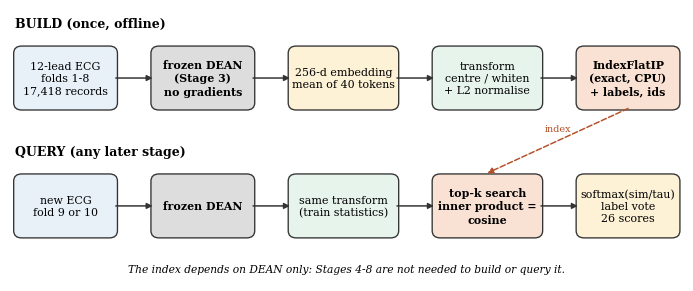

In [7]:
# ---- Figure 1: pipeline schematic ------------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(W2, 2.9)); ax.set_xlim(0, 100); ax.set_ylim(0, 44); ax.axis('off'); ax.grid(False)
def box(x, y, w, h, txt, fc, ec='#333333', fs=6.6, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.25,rounding_size=1.2', fc=fc, ec=ec, lw=0.8))
    ax.text(x + w / 2, y + h / 2, txt, ha='center', va='center', fontsize=fs, fontweight='bold' if bold else 'normal', linespacing=1.25)
def arrow(x0, y0, x1, y1, txt=None, col='#333333', ls='-'):
    ax.annotate('', xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle='-|>', color=col, lw=0.9, ls=ls, shrinkA=0, shrinkB=0))
    if txt: ax.text((x0 + x1) / 2, (y0 + y1) / 2 + 1.6, txt, ha='center', fontsize=5.8, color=col)
ax.text(0.5, 42, 'BUILD (once, offline)', fontsize=7.5, fontweight='bold', va='center')
box(0.5, 28, 15, 10, '12-lead ECG\nfolds 1-8\n17,418 records', '#E8F1F8')
box(21, 28, 15, 10, 'frozen DEAN\n(Stage 3)\nno gradients', '#DDDDDD', bold=True)
box(41.5, 28, 16, 10, '256-d embedding\nmean of 40 tokens', '#FDF1D6')
box(63, 28, 16, 10, 'transform\ncentre / whiten\n+ L2 normalise', '#E6F4EC')
box(84.5, 28, 15, 10, 'IndexFlatIP\n(exact, CPU)\n+ labels, ids', '#F9E1D3', bold=True)
for a, b in [(15.5, 21), (36, 41.5), (57.5, 63), (79, 84.5)]: arrow(a, 33, b, 33)
ax.text(0.5, 21, 'QUERY (any later stage)', fontsize=7.5, fontweight='bold', va='center')
box(0.5, 7, 15, 10, 'new ECG\nfold 9 or 10', '#E8F1F8')
box(21, 7, 15, 10, 'frozen DEAN', '#DDDDDD', bold=True)
box(41.5, 7, 16, 10, 'same transform\n(train statistics)', '#E6F4EC')
box(63, 7, 16, 10, 'top-k search\ninner product =\ncosine', '#F9E1D3', bold=True)
box(84.5, 7, 15, 10, 'softmax(sim/tau)\nlabel vote\n26 scores', '#FDF1D6')
for a, b in [(15.5, 21), (36, 41.5), (57.5, 63), (79, 84.5)]: arrow(a, 12, b, 12)
arrow(92, 28, 71, 17.4, 'index', '#B5502A', '--')
ax.text(50, 1.2, 'The index depends on DEAN only: Stages 4-8 are not needed to build or query it.', ha='center', fontsize=6.4, style='italic')
save_fig(fig, 'fig01_pipeline')

effective dimension (participation ratio) 6.8 of 256 | axes for 90% / 99% of the variance: 33 / 157
  random-pair cosine, cosine            : mean +0.946  sd 0.041
  random-pair cosine, centered          : mean +0.028  sd 0.396
  random-pair cosine, whiten (eps 0.1)  : mean +0.002  sd 0.081


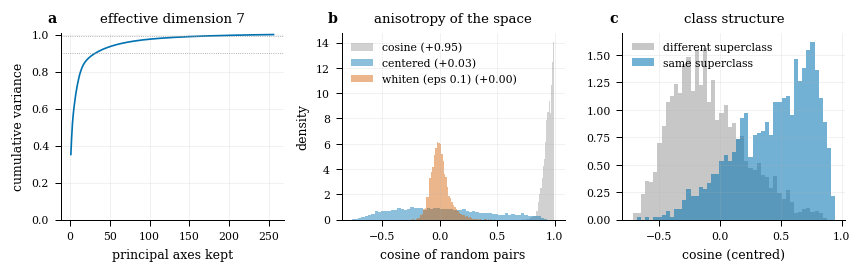

In [8]:
# ---- geometry statistics ---------------------------------------------------------------------------------------------
rng_g = np.random.default_rng(CFG['seed'])
Zc = Z_tr.astype(np.float64) - Z_tr.mean(0)
EV = np.sort(np.linalg.eigvalsh(Zc.T @ Zc / (NTR - 1)))[::-1]
EV = np.maximum(EV, 0)
cum_var = np.cumsum(EV) / EV.sum()
EFF_DIM = float(EV.sum() ** 2 / (EV ** 2).sum())
pair = rng_g.integers(0, NTR, (6000, 2)); pair = pair[pair[:, 0] != pair[:, 1]]
def pair_cos(tr):
    X = PL.apply_transform(Z_tr[np.unique(pair)], tr); pos = {g: i for i, g in enumerate(np.unique(pair))}
    return (X[[pos[a] for a in pair[:, 0]]] * X[[pos[b] for b in pair[:, 1]]]).sum(1)
GEO_TR = OrderedDict([('cosine', PL.fit_transform(Z_tr, 'cosine')), ('centered', PL.fit_transform(Z_tr, 'centered')), ('whiten (eps 0.1)', PL.fit_transform(Z_tr, 'whiten', eps=0.1))])
GEO_COS = OrderedDict((k, pair_cos(t)) for k, t in GEO_TR.items())
print(f'effective dimension (participation ratio) {EFF_DIM:.1f} of {Z_tr.shape[1]} | axes for 90% / 99% of the variance: {int(np.searchsorted(cum_var, .9)) + 1} / {int(np.searchsorted(cum_var, .99)) + 1}')
for k, v in GEO_COS.items(): print(f'  random-pair cosine, {k:18s}: mean {v.mean():+.3f}  sd {v.std():.3f}')
# same-superclass vs different-superclass similarity under the centred transform (the geometry retrieval relies on)
Xc_tr = PL.apply_transform(Z_tr, GEO_TR['centered'])
sup_lab = Y_tr[:, :5].argmax(1); sup_one = Y_tr[:, :5].sum(1) == 1
n_pp = min(4000, int(sup_one.sum())); ii = rng_g.choice(np.where(sup_one)[0], n_pp, replace=True); jj = rng_g.choice(np.where(sup_one)[0], n_pp, replace=True)
okp = ii != jj; ii, jj = ii[okp], jj[okp]
c_ij = (Xc_tr[ii] * Xc_tr[jj]).sum(1); same_ij = sup_lab[ii] == sup_lab[jj]

fig, ax = plt.subplots(1, 3, figsize=(W2, 2.3))
ax[0].plot(np.arange(1, len(EV) + 1), cum_var, color=C_KNN)
for q in (.9, .99): ax[0].axhline(q, color='#999999', lw=0.5, ls=':')
ax[0].set_xlabel('principal axes kept'); ax[0].set_ylabel('cumulative variance'); ax[0].set_title(f'effective dimension {EFF_DIM:.0f}'); ax[0].set_ylim(0, 1.01); panel(ax[0], 'a')
for (k, v), c in zip(GEO_COS.items(), ['#999999', C_KNN, '#D55E00']):
    ax[1].hist(v, bins=60, histtype='stepfilled', alpha=0.45, color=c, label=f'{k} ({v.mean():+.2f})', density=True)
ax[1].set_xlabel('cosine of random pairs'); ax[1].set_ylabel('density'); ax[1].legend(loc='upper left'); ax[1].set_title('anisotropy of the space'); panel(ax[1], 'b')
bins = np.linspace(c_ij.min(), c_ij.max(), 50)
ax[2].hist(c_ij[~same_ij], bins=bins, alpha=0.55, color='#999999', density=True, label='different superclass')
ax[2].hist(c_ij[same_ij], bins=bins, alpha=0.55, color=C_KNN, density=True, label='same superclass')
ax[2].set_xlabel('cosine (centred)'); ax[2].set_title('class structure'); ax[2].legend(); panel(ax[2], 'c')
fig.tight_layout(); save_fig(fig, 'fig02_embedding_geometry')

## 6. Choosing the transform and the retrieval settings
Six transforms × five neighbour counts × five temperatures (150 configurations) are scored on fold 9 as macro AUC over the reliable labels, with the transform fitted on folds 1–8 only. Selecting the best of 150 on the data it is scored on is optimistic, so the selection is **cross-fitted**: fold 9 is split in two random halves, the best configuration is chosen on one half and scored on the other (both directions), and the mean of the two held-out scores is the number reported. The configuration stored with the index is the best one on all of fold 9; its held-out estimate is the cross-fit number, not its own score.

In [9]:
def auc_cols(Y, S):
    npos = Y.sum(0); nneg = len(Y) - npos
    r = rankdata(S, axis=0)
    with np.errstate(invalid='ignore', divide='ignore'):
        a = ((r * Y).sum(0) - npos * (npos + 1) / 2) / (npos * nneg)
    a[(npos == 0) | (nneg == 0)] = np.nan
    return a
assert np.allclose(np.nan_to_num(auc_cols(Y_va, LG_va)[REL]), np.nan_to_num(auc_per_label(Y_va, LG_va, 1)[REL]), atol=1e-9), 'fast AUC disagrees with eval_lib'
def macro(a, m=None):
    return float(np.nanmean(a[REL if m is None else m]))
rng_h = np.random.default_rng(CFG['seed']); perm_h = rng_h.permutation(NVA)
HALF = [np.sort(perm_h[:NVA // 2]), np.sort(perm_h[NVA // 2:])]
KS = [k for k in CFG['k_grid'] if k <= min(CFG['k_max'], NTR - 1)]
TAUS = CFG['tau_grid']
tau_name = lambda t: 'uniform' if t is None else f'{t:g}'
HEAD_AUC = auc_cols(Y_va, LG_va); HEAD_HALF = [auc_cols(Y_va[h], LG_va[h]) for h in HALF]

def prototypes(X, Y):
    cnt = Y.sum(0)
    P = (Y.T @ X) / np.maximum(cnt[:, None], 1)
    return PL.l2n(P), cnt > 0

rows, VSTATE = [], OrderedDict()
t0 = time.time()
for vn, vp in CFG['variants'].items():
    tr = PL.fit_transform(Z_tr, **vp)
    Xtr, Xva = PL.apply_transform(Z_tr, tr), PL.apply_transform(Z_va, tr)
    ix = PL.build_index(Xtr)
    Dv, Iv = ix.search(Xva, min(CFG['k_max'], NTR))
    P, has = prototypes(Xtr, Y_tr)
    S_p = Xva @ P.T; S_p[:, ~has] = 0
    VSTATE[vn] = dict(tr=tr, D=Dv, I=Iv, proto_auc=auc_cols(Y_va, S_p), proto_half=[auc_cols(Y_va[h], S_p[h]) for h in HALF])
    for k in KS:
        for t in TAUS:
            S = PL.knn_scores(Dv, Iv, Y_tr, k, t)
            rows.append(dict(variant=vn, k=k, tau=tau_name(t), tau_val=np.nan if t is None else t, auc=macro(auc_cols(Y_va, S)),
                             auc_A=macro(auc_cols(Y_va[HALF[0]], S[HALF[0]])), auc_B=macro(auc_cols(Y_va[HALF[1]], S[HALF[1]]))))
GRID = pd.DataFrame(rows)
print(f'{len(GRID)} configurations scored in {time.time() - t0:.0f} s')
GRID.to_csv(os.path.join(TAB_DIR, 'selection_grid.csv'), index=False)
HEAD_M, HEAD_MH = macro(HEAD_AUC), [macro(a) for a in HEAD_HALF]
best = GRID.loc[GRID['auc'].idxmax()]
BEST = dict(variant=best['variant'], k=int(best['k']), tau=None if best['tau'] == 'uniform' else float(best['tau']), auc=float(best['auc']))
XF = []
for sel, ev, col_s, col_e in ((0, 1, 'auc_A', 'auc_B'), (1, 0, 'auc_B', 'auc_A')):
    c = GRID.loc[GRID[col_s].idxmax()]
    XF.append(dict(select_on=f'half {"AB"[sel]}', evaluate_on=f'half {"AB"[ev]}', variant=c['variant'], k=int(c['k']), tau=c['tau'], selected_auc=float(c[col_s]), heldout_auc=float(c[col_e]), head_heldout=HEAD_MH[ev]))
XF = pd.DataFrame(XF); XF.to_csv(os.path.join(TAB_DIR, 'selection_crossfit.csv'), index=False)
XF_KNN, XF_HEAD = float(XF['heldout_auc'].mean()), float(XF['head_heldout'].mean())
OPTIMISM = BEST['auc'] - XF_KNN
print(f'DEAN head macro AUC (fold 9, reliable labels) {HEAD_M:.4f}')
print(f'best on all of fold 9: {BEST}')
print(XF.to_string(index=False))
print(f'cross-fit held-out kNN {XF_KNN:.4f} vs head {XF_HEAD:.4f} on the same halves (difference {XF_KNN - XF_HEAD:+.4f}); selection optimism of the best-of-{len(GRID)} score {OPTIMISM:+.4f}')
TAB_VAR = pd.DataFrame([dict(variant=vn, best_knn_auc=float(GRID[GRID.variant == vn]['auc'].max()), class_prototype_auc=macro(v['proto_auc']),
                             best_k=int(GRID[GRID.variant == vn].sort_values('auc').iloc[-1]['k']), best_tau=GRID[GRID.variant == vn].sort_values('auc').iloc[-1]['tau']) for vn, v in VSTATE.items()])
TAB_VAR.to_csv(os.path.join(TAB_DIR, 'variants.csv'), index=False); print(TAB_VAR.to_string(index=False))

150 configurations scored in 4 s
DEAN head macro AUC (fold 9, reliable labels) 0.9283
best on all of fold 9: {'variant': 'whiten (eps 1)', 'k': 100, 'tau': 0.2, 'auc': 0.9100645125902431}
select_on evaluate_on        variant   k     tau  selected_auc  heldout_auc  head_heldout
   half A      half B whiten (eps 1) 100 uniform      0.915534     0.902274      0.928235
   half B      half A whiten (eps 1) 100     0.2      0.903342     0.915154      0.927813
cross-fit held-out kNN 0.9087 vs head 0.9280 on the same halves (difference -0.0193); selection optimism of the best-of-150 score +0.0014
         variant  best_knn_auc  class_prototype_auc  best_k best_tau
          cosine      0.887468             0.669470     100     0.02
        centered      0.900866             0.897096     100      0.1
  whiten (eps 1)      0.910065             0.924651     100      0.2
whiten (eps 0.1)      0.907381             0.920136     100      0.2
 PCA-64 whitened      0.905694             0.920925     100

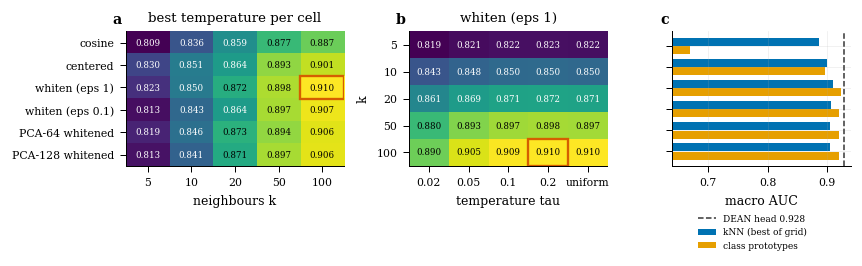

In [10]:
def heat(ax, M, xl, yl, title, vmin=None, vmax=None, fmt='{:.3f}', cmap='viridis', mark=None):
    im = ax.imshow(M, aspect='auto', cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(xl))); ax.set_xticklabels(xl); ax.set_yticks(range(len(yl))); ax.set_yticklabels(yl); ax.grid(False)
    lo, hi = np.nanmin(M) if vmin is None else vmin, np.nanmax(M) if vmax is None else vmax
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if np.isfinite(M[i, j]):
                ax.text(j, i, fmt.format(M[i, j]), ha='center', va='center', fontsize=5.2, color='white' if (M[i, j] - lo) / (hi - lo + 1e-9) < 0.6 else 'black')
    if mark is not None: ax.add_patch(plt.Rectangle((mark[1] - .5, mark[0] - .5), 1, 1, fill=False, ec='#D55E00', lw=1.4))
    ax.set_title(title); return im
VN = list(CFG['variants'])
M1 = np.array([[GRID[(GRID.variant == v) & (GRID.k == k)]['auc'].max() for k in KS] for v in VN])
M2 = np.array([[GRID[(GRID.variant == BEST['variant']) & (GRID.k == k) & (GRID.tau == tau_name(t))]['auc'].iloc[0] for t in TAUS] for k in KS])
fig, ax = plt.subplots(1, 3, figsize=(W2, 2.5), gridspec_kw=dict(width_ratios=[1.1, 1, 0.9]))
heat(ax[0], M1, [str(k) for k in KS], VN, 'best temperature per cell', mark=(VN.index(BEST['variant']), KS.index(BEST['k']))); ax[0].set_xlabel('neighbours k'); panel(ax[0], 'a')
heat(ax[1], M2, [tau_name(t) for t in TAUS], [str(k) for k in KS], f'{BEST["variant"]}', mark=(KS.index(BEST['k']), TAUS.index(BEST['tau']))); ax[1].set_xlabel('temperature tau'); ax[1].set_ylabel('k'); panel(ax[1], 'b')
xx = np.arange(len(VN)); ax[2].barh(xx - .2, TAB_VAR['best_knn_auc'], .38, color=C_KNN, label='kNN (best of grid)')
ax[2].barh(xx + .2, TAB_VAR['class_prototype_auc'], .38, color=C_PROTO, label='class prototypes')
ax[2].axvline(HEAD_M, color=C_HEAD, ls='--', lw=0.9, label=f'DEAN head {HEAD_M:.3f}')
ax[2].set_yticks(xx); ax[2].set_yticklabels([]); ax[2].invert_yaxis()
lo_ = min(TAB_VAR['class_prototype_auc'].min(), TAB_VAR['best_knn_auc'].min(), HEAD_M); ax[2].set_xlim(max(0.5, lo_ - 0.03), max(TAB_VAR['best_knn_auc'].max(), HEAD_M) + 0.012)
ax[2].set_xlabel('macro AUC'); ax[2].legend(loc='upper center', bbox_to_anchor=(0.45, -0.3), fontsize=5.4, ncol=1); panel(ax[2], 'c')
fig.tight_layout(); save_fig(fig, 'fig03_transform_and_grid')

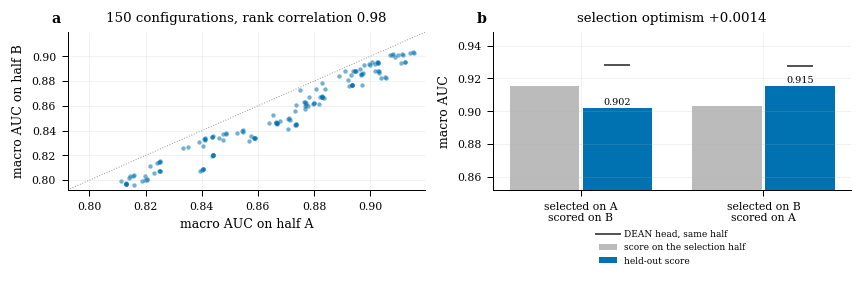

In [11]:
# ---- Figure 4: selection is honest ----------------------------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(W2, 2.5))
ax[0].scatter(GRID['auc_A'], GRID['auc_B'], s=7, alpha=0.55, color=C_KNN, lw=0)
lim = [min(GRID['auc_A'].min(), GRID['auc_B'].min()) - 0.004, max(GRID['auc_A'].max(), GRID['auc_B'].max()) + 0.004]
ax[0].plot(lim, lim, color='#999999', lw=0.6, ls=':'); ax[0].set_xlim(lim); ax[0].set_ylim(lim)
rho = spearmanr(GRID['auc_A'], GRID['auc_B']).correlation
ax[0].set_xlabel('macro AUC on half A'); ax[0].set_ylabel('macro AUC on half B'); ax[0].set_title(f'150 configurations, rank correlation {rho:.2f}'); panel(ax[0], 'a')
lab = ['selected on A\nscored on B', 'selected on B\nscored on A']; xp = np.arange(2)
ax[1].bar(xp - .2, XF['selected_auc'], .38, color='#BBBBBB', label='score on the selection half')
ax[1].bar(xp + .2, XF['heldout_auc'], .38, color=C_KNN, label='held-out score')
ax[1].scatter(xp + .2, XF['head_heldout'], marker='_', s=260, color=C_HEAD, zorder=5, label='DEAN head, same half')
for i in range(2): ax[1].text(i + .2, XF['heldout_auc'].iloc[i] + 0.002, f'{XF["heldout_auc"].iloc[i]:.3f}', ha='center', fontsize=5.8)
ax[1].set_xticks(xp); ax[1].set_xticklabels(lab); ax[1].set_ylabel('macro AUC')
ax[1].set_ylim(max(0.5, min(XF['heldout_auc'].min(), XF['head_heldout'].min()) - 0.05), max(XF['selected_auc'].max(), XF['head_heldout'].max()) + 0.02)
ax[1].set_title(f'selection optimism {OPTIMISM:+.4f}'); ax[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=1, fontsize=5.4); panel(ax[1], 'b')
fig.tight_layout(); save_fig(fig, 'fig04_selection_crossfit')

## 7. Building, saving and re-loading the two indices
Both indices use **one** transform, fitted on folds 1–8, so a single set of parameters is stored and a query is treated identically whichever index it hits. `index_train` (folds 1–8) is the one every fold-9 experiment uses; `index_trainval` (folds 1–9) is for the single test evaluation of Stage 10, when fold 9's labels may legitimately be used. Fold 10 is in neither.

In [12]:
CH = dict(variant=BEST['variant'], k=BEST['k'], tau=BEST['tau'])
TR = VSTATE[CH['variant']]['tr']
X_tr, X_va = PL.apply_transform(Z_tr, TR), PL.apply_transform(Z_va, TR)
Z_all, Y_all = np.concatenate([Z_tr, Z_va]), np.concatenate([Y_tr, Y_va])
X_all = np.concatenate([X_tr, X_va])
idx_all = np.concatenate([tr_idx, va_idx])
PROTO, PROTO_HAS = prototypes(X_tr, Y_tr)
PROTO_ALL, _ = prototypes(X_all, Y_all)
t0 = time.time()
IX_TR, IX_ALL = PL.build_index(X_tr), PL.build_index(X_all)
print(f'chosen: {CH} | indices built in {time.time() - t0:.3f} s | backend: {"faiss IndexFlatIP" if PL.HAVE_FAISS else "numpy reference"}')
PL.save_index(IX_TR, os.path.join(WORK, 'index_train.faiss')); PL.save_index(IX_ALL, os.path.join(WORK, 'index_trainval.faiss'))
np.savez_compressed(os.path.join(WORK, 'prototype_meta.npz'), t_mean=TR['mean'], t_W=(TR['W'] if TR['W'] is not None else np.zeros(0, np.float32)),
                    Y_train=Y_tr, Y_trainval=Y_all, ecg_id_train=ecg_id[tr_idx], ecg_id_trainval=ecg_id[idx_all],
                    fold_train=fold[tr_idx], fold_trainval=fold[idx_all], prototypes_train=PROTO, prototypes_trainval=PROTO_ALL, labels=np.array(LABELS))
CONFIG = dict(schema_version=PL.SCHEMA_VERSION, variant=TR['variant'], n_comp=TR['n_comp'], eps=TR['eps'], k=CH['k'], tau=CH['tau'], dim=int(X_tr.shape[1]),
              n_train=int(len(X_tr)), n_trainval=int(len(X_all)), metric='inner product of L2-normalised vectors (cosine)', backend='faiss.IndexFlatIP' if PL.HAVE_FAISS else 'numpy',
              labels=LABELS, source_checkpoint='dean_finetuned.pt', folds_train=[1, 2, 3, 4, 5, 6, 7, 8], folds_trainval=[1, 2, 3, 4, 5, 6, 7, 8, 9],
              selection=dict(best_val_macro_auc=BEST['auc'], crossfit_heldout_macro_auc=XF_KNN, dean_head_macro_auc=HEAD_M, optimism=OPTIMISM))
json.dump(CONFIG, open(os.path.join(WORK, 'prototype_config.json'), 'w'), indent=1)
np.save(os.path.join(WORK, 'dean_emb_train.npy'), Z_tr); np.save(os.path.join(WORK, 'dean_emb_val.npy'), Z_va)
for f in sorted(os.listdir(WORK)):
    if f.startswith('index_') or f.startswith('prototype_'): print(f'  {f:28s} {os.path.getsize(os.path.join(WORK, f)) / 1e6:7.2f} MB')

# ---- verification -----------------------------------------------------------------------------------------------------
RT = PL.Retriever(WORK, 'train'); RT_ALL = PL.Retriever(WORK, 'trainval')
S_rt, D_rt, I_rt = RT.scores(Z_va)
D_f, I_f = IX_TR.search(X_va, CFG['k_max'])
S_KNN = PL.knn_scores(D_f, I_f, Y_tr, CH['k'], CH['tau'])
check('Retriever reloaded from disk reproduces the in-memory scores', np.allclose(S_rt, S_KNN, atol=1e-5), f'max |diff| {np.abs(S_rt - S_KNN).max():.2e}')
check('indices hold the expected number of vectors', IX_TR.ntotal == NTR and IX_ALL.ntotal == NTR + NVA, f'{IX_TR.ntotal}, {IX_ALL.ntotal}')
check('indexed vectors are unit length', abs(np.linalg.norm(X_tr, axis=1) - 1).max() < 1e-4 and abs(np.linalg.norm(X_all, axis=1) - 1).max() < 1e-4)
ref = PL.build_index(X_tr, force_numpy=True); D_n, I_n = ref.search(X_va, CFG['k_max'])
check('exact index agrees with the numpy reference (similarities)', np.allclose(D_f, D_n, atol=1e-5), f'max |diff| {np.abs(D_f - D_n).max():.2e}')
ov = float(np.mean([len(set(a) & set(b)) / len(a) for a, b in zip(I_f[:, :CFG['k_max']], I_n[:, :CFG['k_max']])]))
check('exact index agrees with the numpy reference (neighbour sets, ties aside)', ov > 0.995, f'mean overlap {ov:.5f}')
Dself, Iself = IX_TR.search(X_tr[:2000], 1)
check('a training vector retrieves itself first', float(np.mean(Dself[:, 0] > 0.9999)) > 0.999, f'{np.mean(Dself[:, 0] > 0.9999):.4f}')
check('index_train contains no fold-9 or fold-10 record', set(ecg_id[tr_idx]).isdisjoint(ecg_id[va_idx]) and (fold[tr_idx] <= 8).all())
check('index_trainval contains folds 1-9 only', fold[idx_all].max() == 9 and RT_ALL.index.ntotal == NTR + NVA)
check('scores are in [0, 1] and finite', bool(np.isfinite(S_KNN).all() and S_KNN.min() >= -1e-6 and S_KNN.max() <= 1 + 1e-6))
np.save(os.path.join(WORK, 'knn_scores_val.npy'), S_KNN)

chosen: {'variant': 'whiten (eps 1)', 'k': 100, 'tau': 0.2} | indices built in 0.040 s | backend: faiss IndexFlatIP
  index_train.faiss              17.84 MB
  index_trainval.faiss           20.07 MB
  prototype_config.json           0.00 MB
  prototype_meta.npz              0.47 MB
[ok] Retriever reloaded from disk reproduces the in-memory scores: max |diff| 0.00e+00
[ok] indices hold the expected number of vectors: 17418, 19601
[ok] indexed vectors are unit length
[ok] exact index agrees with the numpy reference (similarities): max |diff| 0.00e+00
[ok] exact index agrees with the numpy reference (neighbour sets, ties aside): mean overlap 1.00000
[ok] a training vector retrieves itself first: 1.0000
[ok] index_train contains no fold-9 or fold-10 record
[ok] index_trainval contains folds 1-9 only
[ok] scores are in [0, 1] and finite


## 8. Retrieval against the DEAN head
Everything below is on fold 9 with `index_train`, so the queries are unseen. `kNN` is the chosen configuration (exemplar retrieval); `class prototypes` score each label by the cosine to its mean embedding; `DEAN head` is the supervised classifier on the same embedding. Intervals come from a paired bootstrap (one resample of fold 9 shared by all methods). The kNN number is the best-of-150 score and therefore slightly optimistic; the cross-fit estimate of section 6 is the honest one and is shown next to it.

In [13]:
S_PROTO = X_va @ PROTO.T; S_PROTO[:, ~PROTO_HAS] = 0
SCORES = OrderedDict([('DEAN head', LG_va), ('kNN exemplars', S_KNN), ('class prototypes', S_PROTO)])
rng_b = np.random.default_rng(CFG['seed']); BIDX = rng_b.integers(0, NVA, (CFG['n_boot'], NVA))
POINT = {n: auc_cols(Y_va, S) for n, S in SCORES.items()}
BOOT = {n: np.stack([auc_cols(Y_va[ix], S[ix]) for ix in BIDX]) for n, S in SCORES.items()}
SCOPE = dict(all=REL, super=REL & (np.arange(26) < 5), sub=REL & (np.arange(26) >= 5))
def mac(n, sc, boot=False):
    return np.nanmean(BOOT[n][:, SCOPE[sc]], 1) if boot else float(np.nanmean(POINT[n][SCOPE[sc]]))
def dlt(a, b, sc):
    d = np.nanmean(BOOT[a][:, SCOPE[sc]], 1) - np.nanmean(BOOT[b][:, SCOPE[sc]], 1)
    return dict(delta=mac(a, sc) - mac(b, sc), lo=float(np.percentile(d, 2.5)), hi=float(np.percentile(d, 97.5)))
rows = []
for n in SCORES:
    for sc in SCOPE:
        v = mac(n, sc, True); rows.append(dict(method=n, scope=sc, macro_auc=mac(n, sc), lo=float(np.percentile(v, 2.5)), hi=float(np.percentile(v, 97.5)), n_labels=int(SCOPE[sc].sum())))
TAB_MAIN = pd.DataFrame(rows); TAB_MAIN.to_csv(os.path.join(TAB_DIR, 'retrieval_vs_head.csv'), index=False)
print(TAB_MAIN.pivot(index='method', columns='scope', values='macro_auc').round(4).loc[list(SCORES)].to_string())
CMP = OrderedDict()
for a, b in (('kNN exemplars', 'DEAN head'), ('class prototypes', 'DEAN head'), ('kNN exemplars', 'class prototypes')):
    for sc in SCOPE:
        d = dlt(a, b, sc); CMP[(a, b, sc)] = d
        v = 'better' if d['lo'] > 0 else ('worse' if d['hi'] < 0 else 'indistinguishable')
        print(f'{a:17s} - {b:17s} [{sc:5s}] {d["delta"]:+.4f} [{d["lo"]:+.4f}, {d["hi"]:+.4f}]  {v}')
D_KH = CMP[('kNN exemplars', 'DEAN head', 'all')]
NONINF = D_KH['lo'] > -0.01
print(f'non-inferiority of kNN to the head (margin 0.01): {"yes" if NONINF else "no"} | cross-fit held-out kNN {XF_KNN:.4f} vs head {XF_HEAD:.4f}')
pd.DataFrame([dict(a=a, b=b, scope=s, **d) for (a, b, s), d in CMP.items()]).to_csv(os.path.join(TAB_DIR, 'retrieval_deltas.csv'), index=False)

PL_TAB = pd.DataFrame(dict(label=LABELS, family=['super'] * 5 + [FAMILY[l] for l in SUB], n_val_pos=Y_va.sum(0).astype(int), prevalence_train=Y_tr.mean(0), reliable=REL,
                           auc_head=POINT['DEAN head'], auc_knn=POINT['kNN exemplars'], auc_proto=POINT['class prototypes']))
PL_TAB['delta_knn_head'] = PL_TAB['auc_knn'] - PL_TAB['auc_head']; PL_TAB.to_csv(os.path.join(TAB_DIR, 'per_label_auc.csv'), index=False)

scope                all     sub   super
method                                  
DEAN head         0.9283  0.9296  0.9243
kNN exemplars     0.9101  0.9072  0.9191
class prototypes  0.9247  0.9266  0.9183
kNN exemplars     - DEAN head         [all  ] -0.0183 [-0.0265, -0.0101]  worse
kNN exemplars     - DEAN head         [super] -0.0052 [-0.0084, -0.0021]  worse
kNN exemplars     - DEAN head         [sub  ] -0.0224 [-0.0329, -0.0118]  worse
class prototypes  - DEAN head         [all  ] -0.0037 [-0.0059, -0.0014]  worse
class prototypes  - DEAN head         [super] -0.0060 [-0.0082, -0.0040]  worse
class prototypes  - DEAN head         [sub  ] -0.0030 [-0.0060, -0.0002]  worse
kNN exemplars     - class prototypes  [all  ] -0.0146 [-0.0233, -0.0061]  worse
kNN exemplars     - class prototypes  [super] +0.0008 [-0.0022, +0.0040]  indistinguishable
kNN exemplars     - class prototypes  [sub  ] -0.0194 [-0.0306, -0.0084]  worse
non-inferiority of kNN to the head (margin 0.01): no | cross-fi

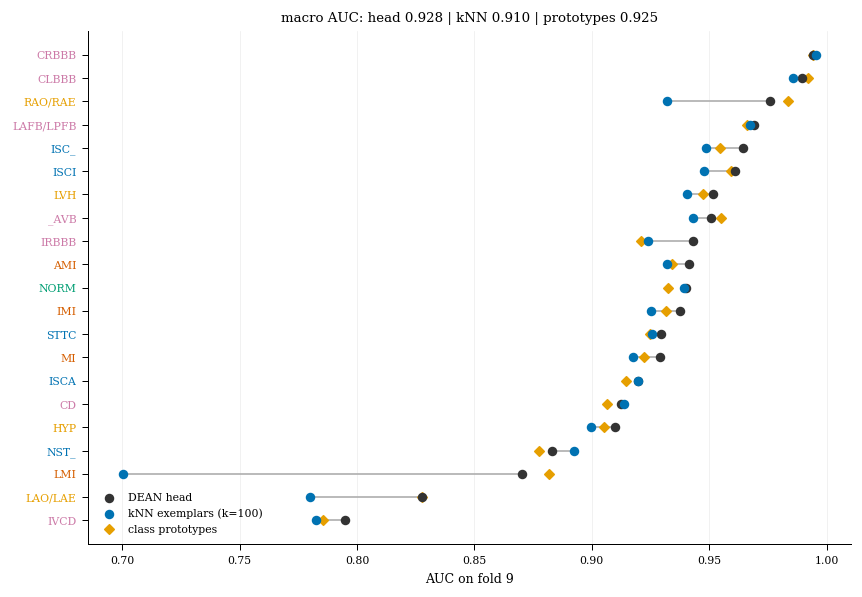

In [14]:
# ---- Figure 5: per-label AUC, head vs kNN ----------------------------------------------------------------------------
order = [i for i in np.argsort(-POINT['DEAN head']) if REL[i]]
fig, ax = plt.subplots(figsize=(W2, 0.19 * len(order) + 1.0))
yy = np.arange(len(order))[::-1]
for y_, i in zip(yy, order):
    ax.plot([POINT['DEAN head'][i], POINT['kNN exemplars'][i]], [y_, y_], color='#BBBBBB', lw=1.2, zorder=1)
ax.scatter(POINT['DEAN head'][order], yy, s=22, color=C_HEAD, zorder=3, label='DEAN head')
ax.scatter(POINT['kNN exemplars'][order], yy, s=22, color=C_KNN, zorder=3, label=f'kNN exemplars (k={CH["k"]})')
ax.scatter(POINT['class prototypes'][order], yy, s=16, marker='D', color=C_PROTO, zorder=2, label='class prototypes')
ax.set_yticks(yy); ax.set_yticklabels([LABELS[i] for i in order])
for t, i in zip(ax.get_yticklabels(), order): t.set_color(SUPER_COL[LABELS[i]] if LABELS[i] in SUPER_COL else SUPER_COL[FAMILY[LABELS[i]]])
ax.set_xlabel('AUC on fold 9'); ax.legend(loc='lower left'); ax.grid(axis='y', alpha=0)
ax.set_title(f'macro AUC: head {mac("DEAN head", "all"):.3f} | kNN {mac("kNN exemplars", "all"):.3f} | prototypes {mac("class prototypes", "all"):.3f}')
fig.tight_layout(); save_fig(fig, 'fig05_per_label_auc')

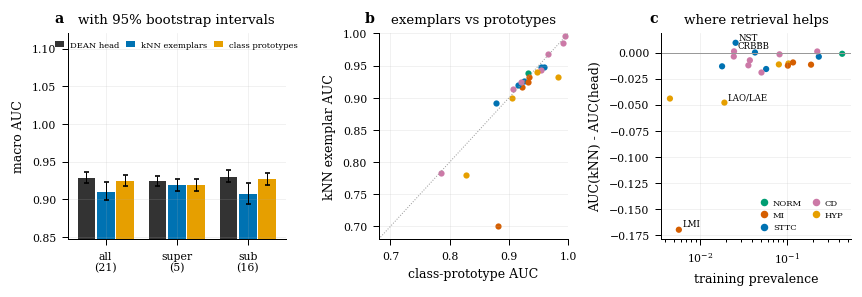

In [15]:
# ---- Figure 6: summary with intervals; exemplars vs prototypes; gain vs prevalence ----------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(W2, 2.5), gridspec_kw=dict(width_ratios=[1.15, 1, 1]))
xs = np.arange(3); cols = [C_HEAD, C_KNN, C_PROTO]
for m, (n, c) in enumerate(zip(SCORES, cols)):
    pt = [mac(n, s) for s in SCOPE]; lo = [np.percentile(mac(n, s, True), 2.5) for s in SCOPE]; hi = [np.percentile(mac(n, s, True), 97.5) for s in SCOPE]
    ax[0].bar(xs + (m - 1) * .27, pt, .25, color=c, label=n, yerr=[np.array(pt) - lo, np.array(hi) - pt], error_kw=dict(lw=0.6, capsize=1.5))
ax[0].set_xticks(xs); ax[0].set_xticklabels([f'{s}\n({int(SCOPE[s].sum())})' for s in SCOPE]); ax[0].set_ylabel('macro AUC')
ymin_ = min(mac(n, s) for n in SCORES for s in SCOPE); ax[0].set_ylim(max(0.5, ymin_ - 0.06), 1.12); ax[0].legend(loc='upper center', ncol=3, fontsize=5, columnspacing=0.8, handlelength=1); ax[0].set_title('with 95% bootstrap intervals'); panel(ax[0], 'a')
for i in np.where(REL)[0]:
    ax[1].scatter(POINT['class prototypes'][i], POINT['kNN exemplars'][i], s=14, color=SUPER_COL[LABELS[i]] if LABELS[i] in SUPER_COL else SUPER_COL[FAMILY[LABELS[i]]], lw=0)
lim = [min(POINT['class prototypes'][REL].min(), POINT['kNN exemplars'][REL].min()) - .02, 1.0]; ax[1].plot(lim, lim, color='#999999', lw=0.6, ls=':'); ax[1].set_xlim(lim); ax[1].set_ylim(lim)
ax[1].set_xlabel('class-prototype AUC'); ax[1].set_ylabel('kNN exemplar AUC'); ax[1].set_title('exemplars vs prototypes'); panel(ax[1], 'b')
dd = PL_TAB[REL]
ax[2].scatter(dd['prevalence_train'], dd['delta_knn_head'], s=14, c=[SUPER_COL[l] if l in SUPER_COL else SUPER_COL[FAMILY[l]] for l in dd['label']], lw=0)
ax[2].axhline(0, color='#999999', lw=0.6); ax[2].set_xscale('log'); ax[2].set_xlabel('training prevalence'); ax[2].set_ylabel('AUC(kNN) - AUC(head)'); ax[2].set_title('where retrieval helps'); panel(ax[2], 'c')
for _, r in dd.sort_values('delta_knn_head').iloc[[0, 1, -2, -1]].iterrows(): ax[2].annotate(r['label'], (r['prevalence_train'], r['delta_knn_head']), fontsize=5.2, xytext=(2, 2), textcoords='offset points')
from matplotlib.lines import Line2D
ax[2].legend(handles=[Line2D([], [], marker='o', ls='', color=c, markersize=3.5, label=k) for k, c in SUPER_COL.items()], ncol=2, loc='lower right', fontsize=5, handletextpad=0.1, columnspacing=0.6)
fig.tight_layout(); save_fig(fig, 'fig06_retrieval_summary')

## 9. Are the retrieved neighbours the right ones?
AUC is a ranking metric. Here the neighbours themselves are inspected: for a fold-9 record with label *j*, how often does a retrieved neighbour carry *j* too (precision at rank), how much better than chance is that (lift), and does the similarity of the closest neighbour tell us when to trust it.

precision at rank 10, reliable superclasses: NORM 0.82 (prev 0.43), MI 0.52 (prev 0.19), STTC 0.61 (prev 0.23), CD 0.67 (prev 0.22), HYP 0.48 (prev 0.10)
top-1 neighbour: mean label Jaccard 0.573 (random record 0.225); identical label set 0.466; median lift@10 over reliable labels 6.4


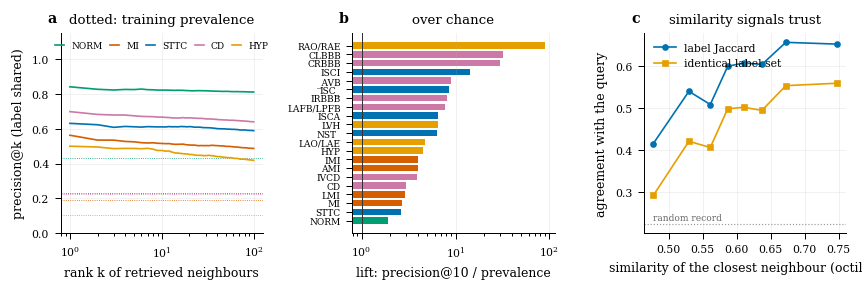

In [16]:
K_ = min(CFG['k_max'], I_f.shape[1]); G = Y_tr[I_f[:, :K_]]                              # (n, K, 26)
PK = np.full((26, K_), np.nan)
for j in range(26):
    pos = Y_va[:, j] == 1
    if pos.sum() >= 1: PK[j] = np.cumsum(G[pos, :, j].mean(0)) / np.arange(1, K_ + 1)
PREV = Y_tr.mean(0); K10 = min(10, K_)
LIFT = PK[:, K10 - 1] / np.maximum(PREV, 1e-9)
jac = lambda a, b: (np.minimum(a, b).sum(1) / np.maximum(np.maximum(a, b).sum(1), 1))
J1 = jac(Y_va, Y_tr[I_f[:, 0]]); EX1 = (Y_va == Y_tr[I_f[:, 0]]).all(1)
rr = np.random.default_rng(1); rp = rr.integers(0, NTR, NVA); J_CH = float(jac(Y_va, Y_tr[rp]).mean())
print(f'precision at rank {K10}, reliable superclasses: ' + ', '.join(f'{LABELS[j]} {PK[j, K10 - 1]:.2f} (prev {PREV[j]:.2f})' for j in range(5)))
print(f'top-1 neighbour: mean label Jaccard {J1.mean():.3f} (random record {J_CH:.3f}); identical label set {EX1.mean():.3f}; median lift@{K10} over reliable labels {np.nanmedian(LIFT[REL]):.1f}')
sim1 = D_f[:, 0]; qb = np.array_split(np.argsort(sim1), 8)
fig, ax = plt.subplots(1, 3, figsize=(W2, 2.45))
for j in range(5): ax[0].plot(np.arange(1, K_ + 1), PK[j], color=SUPER_COL[LABELS[j]], label=LABELS[j]); ax[0].axhline(PREV[j], color=SUPER_COL[LABELS[j]], lw=0.5, ls=':')
ax[0].set_xscale('log'); ax[0].set_xlabel('rank k of retrieved neighbours'); ax[0].set_ylabel('precision@k (label shared)'); ax[0].legend(ncol=5, loc='upper center', fontsize=5.4, columnspacing=0.8, handlelength=1); ax[0].set_title('dotted: training prevalence'); ax[0].set_ylim(0, 1.15); panel(ax[0], 'a')
ordr = [i for i in np.argsort(-LIFT) if REL[i] and np.isfinite(LIFT[i])]
ax[1].barh(np.arange(len(ordr))[::-1], LIFT[ordr], color=[SUPER_COL[LABELS[i]] if LABELS[i] in SUPER_COL else SUPER_COL[FAMILY[LABELS[i]]] for i in ordr], height=0.75)
ax[1].set_yticks(np.arange(len(ordr))[::-1]); ax[1].set_yticklabels([LABELS[i] for i in ordr], fontsize=5.4); ax[1].axvline(1, color='#333333', lw=0.6); ax[1].set_xscale('log')
ax[1].set_xlabel(f'lift: precision@{K10} / prevalence'); ax[1].set_title('over chance'); ax[1].grid(axis='y', alpha=0); panel(ax[1], 'b')
mb = [sim1[b].mean() for b in qb]; ax[2].plot(mb, [J1[b].mean() for b in qb], 'o-', color=C_KNN, ms=3, label='label Jaccard'); ax[2].plot(mb, [EX1[b].mean() for b in qb], 's-', color=C_PROTO, ms=3, label='identical label set')
ax[2].axhline(J_CH, color='#999999', ls=':', lw=0.7); ax[2].text(mb[0], J_CH + 0.01, 'random record', fontsize=5.4, color='#666666')
ax[2].set_xlabel('similarity of the closest neighbour (octiles)'); ax[2].set_ylabel('agreement with the query'); ax[2].legend(loc='upper left'); ax[2].set_title('similarity signals trust'); panel(ax[2], 'c')
fig.tight_layout(); save_fig(fig, 'fig07_neighbour_quality')

## 10. Calibration of the retrieval scores
A neighbour vote is a frequency, so it should be near a probability. Scores are calibrated with a Platt map fitted on one half of fold 9 and applied to the other (both directions), exactly as for the DEAN head in earlier stages; the map keeps the ranking, so the AUC does not change. ECE uses the same equal-mass bins as the rest of the project.

kNN        macro ECE (reliable labels): raw 0.0111 -> calibrated 0.0103
DEAN head  macro ECE (reliable labels): raw 0.1484 -> calibrated 0.0117


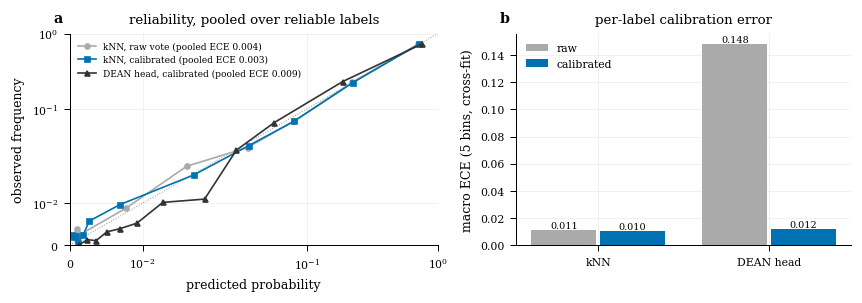

In [17]:
lg = lambda p: np.log(np.clip(p, 1e-3, 1 - 1e-3) / (1 - np.clip(p, 1e-3, 1 - 1e-3)))
Z_KNN = lg(S_KNN)
def crossfit_prob(Zl):
    P = np.zeros_like(Zl)
    for f, t in ((0, 1), (1, 0)):
        a, b = fit_calibration(Zl[HALF[f]], Y_va[HALF[f]], max(2, CFG['min_pos'] // 2)); P[HALF[t]] = sigmoid(Zl[HALF[t]] * a + b)
    return P
P_KNN_RAW, P_KNN_CAL, P_HEAD_CAL = sigmoid(Z_KNN), crossfit_prob(Z_KNN), crossfit_prob(LG_va)
ECE = {}
for nm, Zl in (('kNN', Z_KNN), ('DEAN head', LG_va)):
    raw, cal = eval_lib.crossfit_ece(Zl, Y_va, CFG['min_pos'], seed=CFG['seed'], bins=5); ECE[nm] = (float(np.nanmean(raw[REL])), float(np.nanmean(cal[REL])))
    print(f'{nm:10s} macro ECE (reliable labels): raw {ECE[nm][0]:.4f} -> calibrated {ECE[nm][1]:.4f}')
yv, mk = Y_va[:, REL].ravel(), None
fig, ax = plt.subplots(1, 2, figsize=(W2, 2.55), gridspec_kw=dict(width_ratios=[1.1, 1]))
ax[0].plot([0, 1], [0, 1], color='#999999', lw=0.6, ls=':')
for nm, P, c, mkr in (('kNN, raw vote', P_KNN_RAW, '#AAAAAA', 'o'), ('kNN, calibrated', P_KNN_CAL, C_KNN, 's'), ('DEAN head, calibrated', P_HEAD_CAL, C_HEAD, '^')):
    conf, acc, ece = reliability(yv, P[:, REL].ravel(), 12); ax[0].plot(conf, acc, marker=mkr, ms=3, color=c, label=f'{nm} (pooled ECE {ece:.3f})')
ax[0].set_xscale('symlog', linthresh=0.02); ax[0].set_yscale('symlog', linthresh=0.02); ax[0].set_xlim(0, 1); ax[0].set_ylim(0, 1)
ax[0].set_xlabel('predicted probability'); ax[0].set_ylabel('observed frequency'); ax[0].legend(loc='upper left', fontsize=5.4); ax[0].set_title('reliability, pooled over reliable labels'); panel(ax[0], 'a')
nmz = ['kNN', 'DEAN head']; xe = np.arange(2)
ax[1].bar(xe - .2, [ECE[n][0] for n in nmz], .38, color='#AAAAAA', label='raw'); ax[1].bar(xe + .2, [ECE[n][1] for n in nmz], .38, color=C_KNN, label='calibrated')
for i, n in enumerate(nmz): ax[1].text(i - .2, ECE[n][0], f'{ECE[n][0]:.3f}', ha='center', va='bottom', fontsize=5.8); ax[1].text(i + .2, ECE[n][1], f'{ECE[n][1]:.3f}', ha='center', va='bottom', fontsize=5.8)
ax[1].set_xticks(xe); ax[1].set_xticklabels(nmz); ax[1].set_ylabel('macro ECE (5 bins, cross-fit)'); ax[1].legend(); ax[1].set_title('per-label calibration error'); panel(ax[1], 'b')
fig.tight_layout(); save_fig(fig, 'fig08_calibration')

## 11. The in-sample effect and the size of the index
DEAN was fine-tuned on folds 1–8, so a training record's embedding is more tightly tied to its label than a new record's. Retrieving a training record's neighbours from the training index (itself removed) is therefore an optimistic experiment, and a stronger one still than it looks because PTB-XL has several records per patient and the folds split by patient, not by record. It is reported because later stages (for instance the Chief Resident's training-time retrieval) must not read such numbers as a forecast. The right panel shows how the fold-9 score grows with the number of indexed records.

{'DEAN head fold 1-8 (in-sample)': 0.9811, 'DEAN head fold 9': 0.9283, 'kNN, leave-one-out fold 1-8': 0.9684, 'kNN fold 9': 0.9101}
top-1 similarity: leave-one-out train median 0.6110 vs fold 9 0.5997


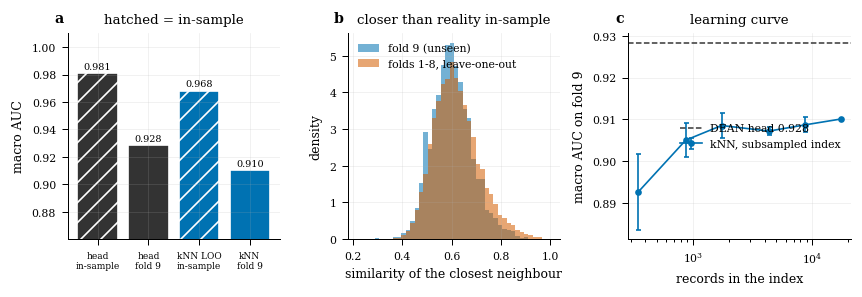

In [18]:
def loo_neighbours(X, ix, K):
    D, I = ix.search(X, K + 1)
    me = np.arange(len(X))[:, None]; m = I == me
    m[~m.any(1), -1] = True                                   # no self in the list (duplicates/ties): drop the last column instead
    return D[~m].reshape(len(X), K), I[~m].reshape(len(X), K)
D_loo, I_loo = loo_neighbours(X_tr, IX_TR, CH['k'] if CH['k'] < NTR - 1 else NTR - 2)
S_LOO = PL.knn_scores(D_loo, I_loo, Y_tr, D_loo.shape[1], CH['tau'])
A_LOO, A_HEAD_TR = auc_cols(Y_tr, S_LOO), auc_cols(Y_tr, LG_tr)
INS = OrderedDict([('DEAN head\nfold 1-8 (in-sample)', macro(A_HEAD_TR)), ('DEAN head\nfold 9', HEAD_M), ('kNN, leave-one-out\nfold 1-8', macro(A_LOO)), ('kNN\nfold 9', macro(POINT['kNN exemplars']))])
print({k.replace('\n', ' '): round(v, 4) for k, v in INS.items()})
print(f'top-1 similarity: leave-one-out train median {np.median(D_loo[:, 0]):.4f} vs fold 9 {np.median(D_f[:, 0]):.4f}')

fr = [f for f in CFG['learning_curve_fracs']]; LC = []
rng_l = np.random.default_rng(CFG['seed'])
for f in fr:
    n = max(int(round(f * NTR)), 2)
    for r in range(1 if f >= 1.0 else CFG['learning_curve_reps']):
        sub = np.sort(rng_l.choice(NTR, n, replace=False)); ixs = PL.build_index(X_tr[sub]); k_ = min(CH['k'], n)
        D_, I_ = ixs.search(X_va, k_)
        LC.append(dict(frac=f, n=n, rep=r, auc=macro(auc_cols(Y_va, PL.knn_scores(D_, I_, Y_tr[sub], k_, CH['tau'])))))
LC = pd.DataFrame(LC); LCg = LC.groupby('n')['auc'].agg(['mean', 'std']).reset_index(); LC.to_csv(os.path.join(TAB_DIR, 'learning_curve.csv'), index=False)

fig, ax = plt.subplots(1, 3, figsize=(W2, 2.5), gridspec_kw=dict(width_ratios=[1, 1, 1.05]))
ax[0].bar(range(4), list(INS.values()), color=[C_HEAD, C_HEAD, C_KNN, C_KNN], alpha=1.0)
for h_, i in zip(ax[0].patches, range(4)): h_.set_hatch('//' if i in (0, 2) else ''); h_.set_edgecolor('white')
for i, v in enumerate(INS.values()): ax[0].text(i, v + 0.003, f'{v:.3f}', ha='center', fontsize=5.8)
ax[0].set_xticks(range(4)); ax[0].set_xticklabels(['head\nin-sample', 'head\nfold 9', 'kNN LOO\nin-sample', 'kNN\nfold 9'], fontsize=5.4); ax[0].set_ylim(max(0.5, min(INS.values()) - 0.05), 1.01); ax[0].set_ylabel('macro AUC'); ax[0].set_title('hatched = in-sample'); panel(ax[0], 'a')
bn = np.linspace(min(D_loo[:, 0].min(), D_f[:, 0].min()), 1.0, 45)
ax[1].hist(D_f[:, 0], bins=bn, alpha=0.55, color=C_KNN, density=True, label='fold 9 (unseen)'); ax[1].hist(D_loo[:, 0], bins=bn, alpha=0.55, color='#D55E00', density=True, label='folds 1-8, leave-one-out')
ax[1].set_xlabel('similarity of the closest neighbour'); ax[1].set_ylabel('density'); ax[1].legend(loc='upper left'); ax[1].set_title('closer than reality in-sample'); panel(ax[1], 'b')
ax[2].errorbar(LCg['n'], LCg['mean'], yerr=LCg['std'].fillna(0), marker='o', ms=3, color=C_KNN, capsize=1.5, label='kNN, subsampled index')
ax[2].axhline(HEAD_M, color=C_HEAD, ls='--', lw=0.9, label=f'DEAN head {HEAD_M:.3f}'); ax[2].set_xscale('log'); ax[2].set_xlabel('records in the index'); ax[2].set_ylabel('macro AUC on fold 9'); ax[2].legend(loc='center right'); ax[2].set_title('learning curve'); panel(ax[2], 'c')
fig.tight_layout(); save_fig(fig, 'fig09_insample_and_index_size')

## 12. The retrieval space and what retrieval returns
Figure 10 projects the transformed embeddings with t-SNE (a visualisation only; nothing is selected from it). Figure 11 shows, for each true label, which labels the neighbour vote hands out: a clean diagonal means neighbours share the query's diagnosis, off-diagonal mass is where the vote confuses one diagnosis with another. Figure 12 lists the neighbours of three fold-9 records, the plain view of what a downstream stage receives.

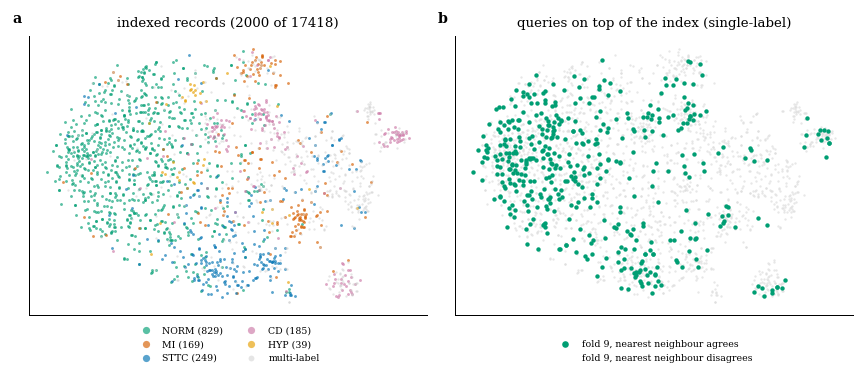

In [19]:
from sklearn.manifold import TSNE
rng_t = np.random.default_rng(CFG['seed']); nt = min(CFG['n_tsne'], NTR + NVA)
n_v = min(NVA, nt // 3); n_t = min(NTR, nt - n_v)
st, sv = rng_t.choice(NTR, n_t, replace=False), rng_t.choice(NVA, n_v, replace=False)
EMB = np.concatenate([X_tr[st], X_va[sv]])
TS = TSNE(n_components=2, perplexity=float(min(30, max(5, (len(EMB) - 1) / 4))), init='pca', random_state=CFG['seed'], learning_rate='auto').fit_transform(EMB)
T_tr, T_va = TS[:n_t], TS[n_t:]
sup1 = lambda Y: np.where(Y[:, :5].sum(1) == 1, Y[:, :5].argmax(1), -1)
lt, lv = sup1(Y_tr[st]), sup1(Y_va[sv])
nn1_ok = (Y_tr[I_f[sv, 0], :5].argmax(1) == Y_va[sv, :5].argmax(1)) & (Y_va[sv, :5].sum(1) == 1) & (Y_tr[I_f[sv, 0], :5].sum(1) == 1)
fig, ax = plt.subplots(1, 2, figsize=(W2, 3.2))
for c in range(5):
    m = lt == c; ax[0].scatter(T_tr[m, 0], T_tr[m, 1], s=3, color=SUPER_COL[SUPER[c]], alpha=0.65, lw=0, label=f'{SUPER[c]} ({int(m.sum())})')
m = lt == -1; ax[0].scatter(T_tr[m, 0], T_tr[m, 1], s=2, color='#CCCCCC', alpha=0.5, lw=0, label='multi-label')
ax[0].legend(markerscale=2.5, ncol=2, loc='lower center', bbox_to_anchor=(0.5, -0.2), fontsize=5.6); ax[0].set_title(f'indexed records ({n_t} of {NTR})'); panel(ax[0], 'a')
ax[1].scatter(T_tr[:, 0], T_tr[:, 1], s=2, color='#DDDDDD', lw=0, alpha=0.7)
one = lv >= 0
ax[1].scatter(T_va[one & nn1_ok, 0], T_va[one & nn1_ok, 1], s=7, color=C_CR, lw=0, label='fold 9, nearest neighbour agrees')
ax[1].scatter(T_va[one & ~nn1_ok, 0], T_va[one & ~nn1_ok, 1], s=9, color='#D55E00', lw=0, marker='x', label='fold 9, nearest neighbour disagrees')
ax[1].legend(loc='lower center', bbox_to_anchor=(0.5, -0.2), markerscale=1.5, fontsize=5.6); ax[1].set_title('queries on top of the index (single-label)'); panel(ax[1], 'b')
for a in ax: a.set_xticks([]); a.set_yticks([]); a.grid(False)
fig.tight_layout(); save_fig(fig, 'fig10_tsne')

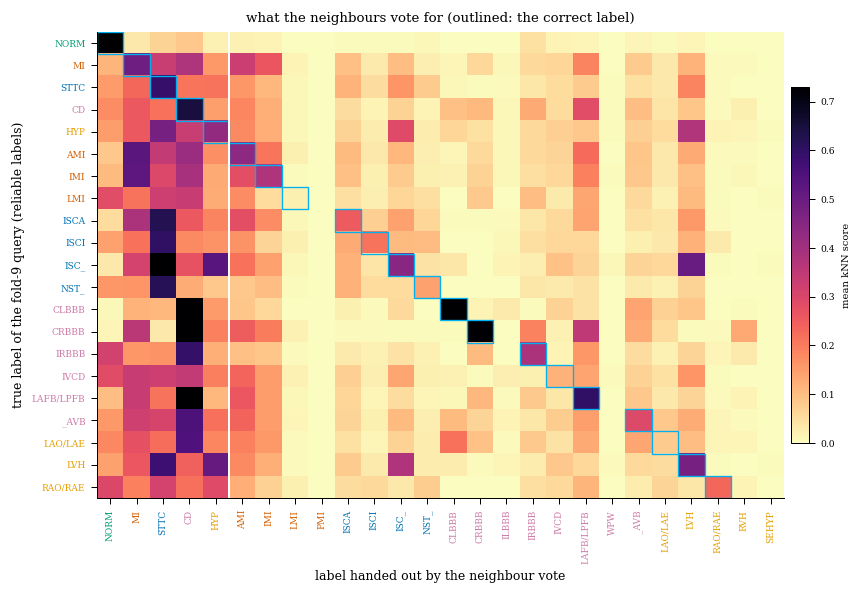

In [20]:
rows_ = np.where(REL)[0]
CO = np.stack([S_KNN[Y_va[:, i] == 1].mean(0) for i in rows_])
fig, ax = plt.subplots(figsize=(W2, 0.17 * len(rows_) + 1.4))
im = ax.imshow(CO, aspect='auto', cmap='magma_r', vmin=0, vmax=max(0.6, float(np.nanpercentile(CO, 99))))
ax.set_xticks(range(26)); ax.set_xticklabels(LABELS, rotation=90, fontsize=5.4); ax.set_yticks(range(len(rows_))); ax.set_yticklabels([LABELS[i] for i in rows_], fontsize=5.4); ax.grid(False)
for t, i in zip(ax.get_yticklabels(), rows_): t.set_color(SUPER_COL[LABELS[i]] if LABELS[i] in SUPER_COL else SUPER_COL[FAMILY[LABELS[i]]])
for t, l in zip(ax.get_xticklabels(), LABELS): t.set_color(SUPER_COL[l] if l in SUPER_COL else SUPER_COL[FAMILY[l]])
for r, i in enumerate(rows_): ax.add_patch(plt.Rectangle((i - .5, r - .5), 1, 1, fill=False, ec='#00B0F0', lw=0.8))
ax.axvline(4.5, color='white', lw=1.2); cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.set_label('mean kNN score', fontsize=6); cb.ax.tick_params(labelsize=5.5)
ax.set_xlabel('label handed out by the neighbour vote'); ax.set_ylabel('true label of the fold-9 query (reliable labels)')
ax.set_title('what the neighbours vote for (outlined: the correct label)'); fig.tight_layout(); save_fig(fig, 'fig11_vote_matrix')

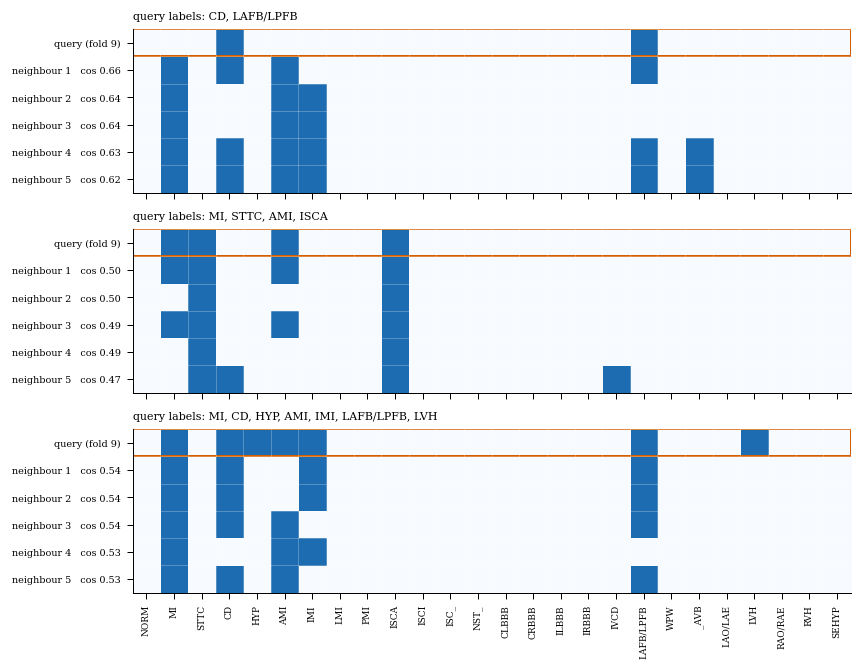

In [21]:
rq = np.random.default_rng(7); cand = np.where(Y_va.sum(1) >= 2)[0]; cand = cand if len(cand) >= 3 else np.arange(NVA)
qs = list(rq.choice(cand, 3, replace=False)); NSHOW = min(5, I_f.shape[1])
fig, axs = plt.subplots(3, 1, figsize=(W2, 5.6), sharex=True)
for a, q in zip(axs, qs):
    M = np.vstack([Y_va[q][None], Y_tr[I_f[q, :NSHOW]]]); a.imshow(M, aspect='auto', cmap='Blues', vmin=0, vmax=1.3); a.grid(False)
    a.set_yticks(range(NSHOW + 1)); a.set_yticklabels(['query (fold 9)'] + [f'neighbour {r + 1}   cos {D_f[q, r]:.2f}' for r in range(NSHOW)], fontsize=5.8)
    a.set_xticks(np.arange(-.5, 26, 1), minor=True); a.set_yticks(np.arange(-.5, NSHOW + 1, 1), minor=True); a.grid(which='minor', color='white', lw=0.6); a.tick_params(which='minor', length=0)
    a.add_patch(plt.Rectangle((-.5, -.5), 26, 1, fill=False, ec='#D55E00', lw=1.2))
    a.set_title('query labels: ' + ', '.join(LABELS[i] for i in np.where(Y_va[q] == 1)[0]), fontsize=6.6, loc='left')
axs[-1].set_xticks(range(26)); axs[-1].set_xticklabels(LABELS, rotation=90, fontsize=5.4)
fig.tight_layout(); save_fig(fig, 'fig12_retrieval_examples')

## 13. Score separation and sensitivity to k
Left: the neighbour vote for fold-9 records that have the superclass versus those that do not. Right: the macro AUC as the number of neighbours changes, with the temperature that is best for each k and with the uniform vote.

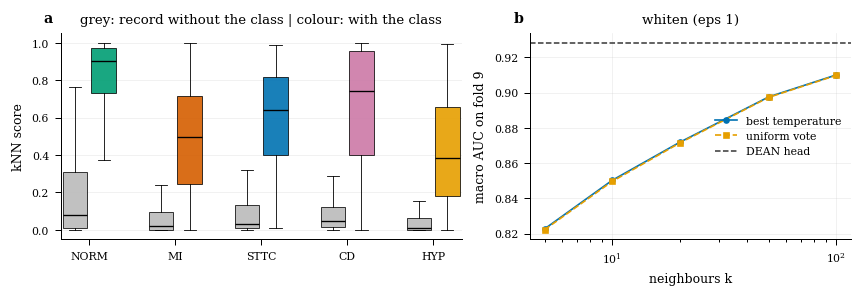

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(W2, 2.5), gridspec_kw=dict(width_ratios=[1.25, 1]))
pos_all = np.arange(5); data, cols_, pos_x = [], [], []
for j in range(5):
    data += [S_KNN[Y_va[:, j] == 0, j], S_KNN[Y_va[:, j] == 1, j]]; cols_ += ['#BBBBBB', SUPER_COL[SUPER[j]]]; pos_x += [j * 3, j * 3 + 1]
bp = ax[0].boxplot(data, positions=pos_x, widths=0.85, patch_artist=True, showfliers=False, medianprops=dict(color='black', lw=0.8), whiskerprops=dict(lw=0.5), capprops=dict(lw=0.5), boxprops=dict(lw=0.5))
for b, c in zip(bp['boxes'], cols_): b.set_facecolor(c); b.set_alpha(0.9)
ax[0].set_xticks([j * 3 + .5 for j in range(5)]); ax[0].set_xticklabels(SUPER); ax[0].set_ylabel('kNN score'); ax[0].set_title('grey: record without the class | colour: with the class'); ax[0].grid(axis='x', alpha=0); panel(ax[0], 'a')
bt = GRID[GRID.variant == CH['variant']]
bestk = bt.groupby('k')['auc'].max(); unik = bt[bt.tau == 'uniform'].set_index('k')['auc']
ax[1].plot(bestk.index, bestk.values, 'o-', ms=3, color=C_KNN, label='best temperature'); ax[1].plot(unik.index, unik.values, 's--', ms=3, color=C_PROTO, label='uniform vote')
ax[1].axhline(HEAD_M, color=C_HEAD, ls='--', lw=0.9, label='DEAN head'); ax[1].set_xscale('log'); ax[1].set_xlabel('neighbours k'); ax[1].set_ylabel('macro AUC on fold 9'); ax[1].legend(loc='center right'); ax[1].set_title(CH['variant']); panel(ax[1], 'b')
fig.tight_layout(); save_fig(fig, 'fig13_separation_and_k')

## 14. Fusion preview (not a decision)
Stage 10 decides how retrieval is combined with the classifier. This section only checks that the index carries information the classifier lacks. Each score is converted to its rank within the label (so no calibration is fitted and nothing can leak), and the two are mixed as `(1 - a) * rank(classifier) + a * rank(kNN)`. The mixing weight is chosen on one half of fold 9 and scored on the other; the fixed weight a = 0.5, chosen before looking, is reported with a bootstrap interval. If Stage 8's outputs are attached, the Chief Resident is previewed too.

DEAN head      : alone 0.9283 | a=0.5 0.9280 (gain -0.0003, CI [-0.0028, +0.0021]) | kNN alone 0.9101 | cross-fit gain +0.0005 at a = [0.3, 0.1]
Chief Resident : alone 0.9125 | a=0.5 0.9235 (gain +0.0110, CI [+0.0077, +0.0143]) | kNN alone 0.9101 | cross-fit gain +0.0113 at a = [0.6, 0.7]


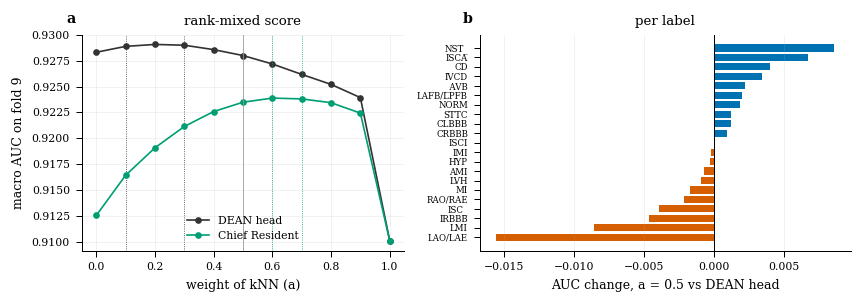

In [23]:
def rk(S): return (rankdata(S, axis=0) - 0.5) / len(S)
BASES = OrderedDict([('DEAN head', LG_va)])
p_cr = find_art('cr_logits_val.npy')
if p_cr:
    L_cr = np.load(p_cr)
    if L_cr.shape == (NVA, 26) and np.isfinite(L_cr).all() and float(np.nanmean(auc_cols(Y_va, L_cr)[REL])) > 0.8: BASES['Chief Resident'] = L_cr
    else: print('cr_logits_val.npy found but its shape or AUC is not plausible for this split; Chief Resident preview skipped')
else: print('Stage-8 outputs not attached: Chief Resident preview skipped')
ALPHAS = np.round(np.linspace(0, 1, 11), 2); R_KNN = rk(S_KNN); FUS = OrderedDict()
for bn_, Sb in BASES.items():
    Rb = rk(Sb); curves = np.array([[macro(auc_cols(Y_va, (1 - a) * Rb + a * R_KNN))] for a in ALPHAS]).ravel()
    half = [np.array([macro(auc_cols(Y_va[h], ((1 - a) * Rb + a * R_KNN)[h])) for a in ALPHAS]) for h in HALF]
    cf = []
    for s_, e_ in ((0, 1), (1, 0)):
        a_s = int(np.argmax(half[s_])); cf.append(dict(alpha=float(ALPHAS[a_s]), heldout=float(half[e_][a_s]), base=float(half[e_][0])))
    mid = (Rb * 0.5 + R_KNN * 0.5); b_mid = np.stack([auc_cols(Y_va[ix], mid[ix]) for ix in BIDX]); b_base = np.stack([auc_cols(Y_va[ix], Sb[ix]) for ix in BIDX])
    dd_ = np.nanmean(b_mid[:, REL], 1) - np.nanmean(b_base[:, REL], 1)
    FUS[bn_] = dict(curve=curves, crossfit=cf, xf_gain=float(np.mean([c['heldout'] - c['base'] for c in cf])), mid_delta=float(np.nanmean(auc_cols(Y_va, mid)[REL]) - macro(auc_cols(Y_va, Sb))),
                    mid_lo=float(np.percentile(dd_, 2.5)), mid_hi=float(np.percentile(dd_, 97.5)), per_label=auc_cols(Y_va, mid) - auc_cols(Y_va, Sb))
    print(f'{bn_:15s}: alone {curves[0]:.4f} | a=0.5 {curves[5]:.4f} (gain {FUS[bn_]["mid_delta"]:+.4f}, CI [{FUS[bn_]["mid_lo"]:+.4f}, {FUS[bn_]["mid_hi"]:+.4f}]) | kNN alone {curves[-1]:.4f} | cross-fit gain {FUS[bn_]["xf_gain"]:+.4f} at a = {[c["alpha"] for c in FUS[bn_]["crossfit"]]}')
fig, ax = plt.subplots(1, 2, figsize=(W2, 2.55), gridspec_kw=dict(width_ratios=[1, 1.15]))
for (bn_, f), c in zip(FUS.items(), [C_HEAD, C_CR]):
    ax[0].plot(ALPHAS, f['curve'], 'o-', ms=3, color=c, label=bn_)
    for cf_ in f['crossfit']: ax[0].axvline(cf_['alpha'], color=c, lw=0.5, ls=':')
ax[0].axvline(0.5, color='#999999', lw=0.5); ax[0].set_xlabel('weight of kNN (a)'); ax[0].set_ylabel('macro AUC on fold 9'); ax[0].legend(loc='lower center'); ax[0].set_title('rank-mixed score'); panel(ax[0], 'a')
bn0 = list(FUS)[0]; pl_ = FUS[bn0]['per_label']; od = [i for i in np.argsort(pl_) if REL[i] and np.isfinite(pl_[i])]
ax[1].barh(np.arange(len(od)), pl_[od], color=[C_KNN if pl_[i] >= 0 else '#D55E00' for i in od], height=0.75); ax[1].set_yticks(np.arange(len(od))); ax[1].set_yticklabels([LABELS[i] for i in od], fontsize=5.2)
ax[1].axvline(0, color='black', lw=0.6); ax[1].set_xlabel(f'AUC change, a = 0.5 vs {bn0}'); ax[1].grid(axis='y', alpha=0); ax[1].set_title('per label'); panel(ax[1], 'b')
fig.tight_layout(); save_fig(fig, 'fig14_fusion_preview')

## 15. Speed and memory of the CPU index
Latency is the median over single queries (the case of one record at a time) and throughput the time for a batch. A flat index scans every vector, so the cost is linear in the number of records; the figure shows that at this scale exact search is cheap enough that no approximation is justified.

          backend     n     mb  ms_single  ms_p95  qps_batch
  numpy reference  1000  1.024      0.116   0.154  86474.894
faiss IndexFlatIP  1000  1.024      0.051   0.069  37751.372
  numpy reference  2000  2.048      0.112   0.137  49900.009
faiss IndexFlatIP  2000  2.048      0.105   0.122  13426.182
  numpy reference  4000  4.096      0.194   2.448  27278.143
faiss IndexFlatIP  4000  4.096      0.196   0.228   5882.009
  numpy reference  8000  8.192      0.312   0.700  13549.847
faiss IndexFlatIP  8000  8.192      0.366   0.390   6546.227
  numpy reference 17418 17.836      0.564   0.642   5335.832
faiss IndexFlatIP 17418 17.836      1.331   4.576   3130.725


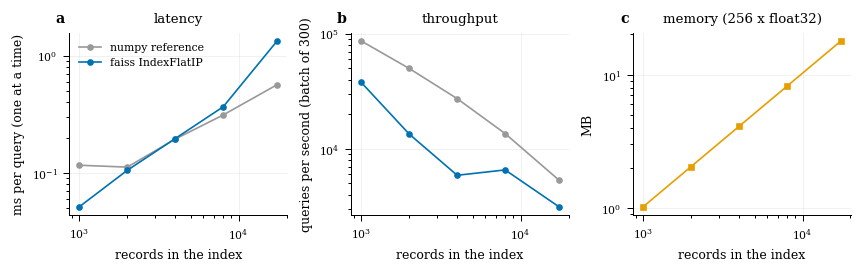

In [24]:
def bench(make, X, Q, n_single=100):
    ix = make(X); ix.search(Q[:8], 10)
    one = []
    for q in Q[:n_single]:
        t = time.perf_counter(); ix.search(q[None], 10); one.append(time.perf_counter() - t)
    bt = []
    for _ in range(3):
        t = time.perf_counter(); ix.search(Q, 10); bt.append(time.perf_counter() - t)
    return dict(ms_single=1e3 * float(np.median(one)), ms_p95=1e3 * float(np.percentile(one, 95)), qps_batch=len(Q) / float(np.median(bt)))
sizes = sorted(set(min(s, NTR) for s in CFG['bench_sizes'])); Qb = X_va[:CFG['bench_queries']]
BACK = OrderedDict([('numpy reference', lambda X: PL.build_index(X, force_numpy=True))])
if PL.HAVE_FAISS: BACK['faiss IndexFlatIP'] = lambda X: PL.build_index(X)
BR = []
for n in sizes:
    for bn_, mk in BACK.items(): BR.append(dict(backend=bn_, n=n, mb=n * X_tr.shape[1] * 4 / 1e6, **bench(mk, X_tr[:n], Qb)))
BR = pd.DataFrame(BR); BR.to_csv(os.path.join(TAB_DIR, 'benchmark.csv'), index=False); print(BR.round(3).to_string(index=False))
fig, ax = plt.subplots(1, 3, figsize=(W2, 2.3))
for (bn_, g), c in zip(BR.groupby('backend', sort=False), ['#999999', C_KNN]):
    ax[0].plot(g['n'], g['ms_single'], 'o-', ms=3, color=c, label=bn_); ax[1].plot(g['n'], g['qps_batch'], 'o-', ms=3, color=c, label=bn_)
ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].set_xlabel('records in the index'); ax[0].set_ylabel('ms per query (one at a time)'); ax[0].legend(); ax[0].set_title('latency'); panel(ax[0], 'a')
ax[1].set_xscale('log'); ax[1].set_yscale('log'); ax[1].set_xlabel('records in the index'); ax[1].set_ylabel(f'queries per second (batch of {len(Qb)})'); ax[1].set_title('throughput'); panel(ax[1], 'b')
g0 = BR[BR.backend == list(BACK)[-1]]; ax[2].plot(g0['n'], g0['mb'], 's-', ms=3, color=C_PROTO, label='vectors in RAM'); ax[2].set_xscale('log'); ax[2].set_yscale('log')
ax[2].set_xlabel('records in the index'); ax[2].set_ylabel('MB'); ax[2].set_title('memory (256 x float32)'); panel(ax[2], 'c')
fig.tight_layout(); save_fig(fig, 'fig15_index_speed')

## 16. Checks, summary and export

In [25]:
check('the chosen configuration was selected without fold 10 and without any Stage 4-8 output', True, 'DEAN embeddings + fold 9 labels only')
check('kNN retrieval carries real signal (macro AUC > 0.75)', mac('kNN exemplars', 'all') > 0.75, f'{mac("kNN exemplars", "all"):.4f}', level='warn')
check('selection optimism is small (< 0.01 macro AUC)', OPTIMISM < 0.01, f'{OPTIMISM:+.4f}', level='warn')
check('closest neighbours are better than random records', float(J1.mean()) > J_CH, f'Jaccard {J1.mean():.3f} vs {J_CH:.3f}')
check('retrieval beats chance in precision@k for every reliable superclass', all(PK[j, K10 - 1] > PREV[j] for j in range(5) if REL[j] and np.isfinite(PK[j, K10 - 1])))
K_LOO, K_V9 = INS['kNN, leave-one-out\nfold 1-8'], INS['kNN\nfold 9']
check('leave-one-out is more optimistic than fold 9 (the in-sample effect is real)', K_LOO >= K_V9 - 1e-6, f'{K_LOO:.4f} vs {K_V9:.4f}', level='warn')
need = ['index_train.faiss', 'index_trainval.faiss', 'prototype_meta.npz', 'prototype_config.json', 'proto_lib.py', 'dean_emb_train.npy', 'dean_emb_val.npy', 'knn_scores_val.npy']
if not PL.HAVE_FAISS: need[:2] = ['index_train.faiss.npy', 'index_trainval.faiss.npy']
check('every deliverable file exists', all(os.path.exists(os.path.join(WORK, f)) for f in need), [f for f in need if not os.path.exists(os.path.join(WORK, f))])
NFIG = len(glob.glob(os.path.join(FIG_DIR, '*.png')))
check('all 15 figures were written (png and pdf)', NFIG == 15 and len(glob.glob(os.path.join(FIG_DIR, '*.pdf'))) == 15, NFIG)
CHK = pd.DataFrame(CHECKS); CHK.to_csv(os.path.join(TAB_DIR, 'checks.csv'), index=False)
print(CHK[['check', 'status']].to_string(index=False))
nfail = int((CHK.status == 'FAIL').sum()); nwarn = int((CHK.status == 'WARN').sum())
print(f'\n{int((CHK.status == "PASS").sum())} pass, {nwarn} warn, {nfail} fail')
if CFG['strict'] and nfail: raise AssertionError(f'{nfail} check(s) failed, see the table above')

METRICS = dict(
    versions=VERSIONS, backend=CONFIG['backend'], chosen=CH, config_file='prototype_config.json',
    dean_head_macro_auc=HEAD_M, knn_macro_auc_best_of_grid=BEST['auc'], knn_macro_auc_crossfit=XF_KNN, head_macro_auc_crossfit_halves=XF_HEAD, selection_optimism=OPTIMISM,
    class_prototype_macro_auc=mac('class prototypes', 'all'),
    knn_minus_head=D_KH, knn_noninferior_to_head_margin_0_01=bool(NONINF),
    by_scope={sc: {n: mac(n, sc) for n in SCORES} for sc in SCOPE},
    neighbour_quality=dict(top1_label_jaccard=float(J1.mean()), random_jaccard=J_CH, top1_identical_label_set=float(EX1.mean()), median_lift_at_10=float(np.nanmedian(LIFT[REL])), effective_dimension=EFF_DIM),
    in_sample={k.replace('\n', ' '): v for k, v in INS.items()},
    ece={k: dict(raw=v[0], calibrated=v[1]) for k, v in ECE.items()},
    fusion_preview={k: dict(alpha0_5_delta=v['mid_delta'], ci=[v['mid_lo'], v['mid_hi']], crossfit_gain=v['xf_gain']) for k, v in FUS.items()},
    benchmark=BR.to_dict('records'), n_train=NTR, n_val=NVA, n_reliable_labels=int(REL.sum()), checks=dict(pass_=int((CHK.status == 'PASS').sum()), warn=nwarn, fail=nfail),
    runtime_minutes=(time.time() - NB_T0) / 60)
json.dump(METRICS, open(os.path.join(WORK, 'prototype_metrics.json'), 'w'), indent=1, default=float)
print('\n' + '=' * 100)
print(f'DEAN head macro AUC (fold 9)               {HEAD_M:.4f}')
print(f'kNN exemplars, best of {len(GRID)} configs          {BEST["auc"]:.4f}   <- optimistic by selection')
print(f'kNN exemplars, cross-fit held-out          {XF_KNN:.4f}   (head on the same halves {XF_HEAD:.4f})')
print(f'class prototypes                           {mac("class prototypes", "all"):.4f}')
print(f'kNN minus head [95% CI]                    {D_KH["delta"]:+.4f} [{D_KH["lo"]:+.4f}, {D_KH["hi"]:+.4f}]  non-inferior (0.01): {"yes" if NONINF else "no"}')
print(f'chosen: transform {CH["variant"]}, k {CH["k"]}, tau {tau_name(CH["tau"])} | indices: {NTR} and {NTR + NVA} vectors of dimension {X_tr.shape[1]}')
print(f'total run time {(time.time() - NB_T0) / 60:.1f} min')
print('=' * 100)
print('Publish /kaggle/working as the Dataset prototype-index-v1.')

[ok] the chosen configuration was selected without fold 10 and without any Stage 4-8 output: DEAN embeddings + fold 9 labels only
[ok] kNN retrieval carries real signal (macro AUC > 0.75): 0.9101
[ok] selection optimism is small (< 0.01 macro AUC): +0.0014
[ok] closest neighbours are better than random records: Jaccard 0.573 vs 0.225
[ok] retrieval beats chance in precision@k for every reliable superclass
[ok] leave-one-out is more optimistic than fold 9 (the in-sample effect is real): 0.9684 vs 0.9101
[ok] every deliverable file exists: []
[ok] all 15 figures were written (png and pdf): 15
                                                                                              check status
                                                   split: training = folds 1-8, validation = fold 9   PASS
                                                                 split: fold 10 is in neither index   PASS
                                                                              emb

## Reading the result
* **What Stage 9 delivers.** Two exact CPU indices over frozen DEAN embeddings, the transform that goes with them, the labels and record ids of every indexed record, the class prototypes, and `Retriever` in `proto_lib.py`. Later stages load them with `PL.Retriever('/kaggle/input/prototype-index-v1', 'train')` (fold-9 experiments) or `'trainval'` (the one test evaluation).
* **How good is it.** The honest comparison is the cross-fit held-out number against the head on the same halves, and the paired interval of section 8. If kNN is below the head, retrieval is a complement and not a replacement; section 14 says whether it adds anything when mixed in.
* **What not to do with it.** Do not read train-against-train retrieval as a forecast (section 11), and do not tune the weight of retrieval on fold 10.
* **Nothing here touches fold 10.** The test records are queried once, in Stage 10, against `index_trainval`.